# Where should the next riyal go?

<div style="box-sizing:border-box;max-width:100%;overflow-wrap:break-word;background:rgba(57,135,229,.12);border-left:6px solid #3987e5;padding:16px 22px;border-radius:0 12px 12px 0;font-size:15px;line-height:1.6">
<div style="color:#3987e5;font-weight:600;letter-spacing:.06em;font-size:12px;margin-bottom:6px">SAUDI NONPROFIT GIVING ON EHSAN · 2021–2026</div>
<p style="margin:0 0 10px"><b>The question.</b> If a funder had to choose where grants and new associations should go next, which <b style="color:#3987e5">region × cause</b> combinations should come first, and why?</p>
<p style="margin:0"><b>The data.</b> Every donation opportunity published on Ehsan, the national donation platform, from February 2021 to October 2026: where it was, what it was for, which association ran it, how much it raised, and <b style="color:#3987e5">how fast</b>. Collected from Ehsan's public pages (see the appendix).</p>
</div>

<div style="box-sizing:border-box;max-width:100%;overflow-wrap:break-word;background:rgba(127,127,127,.08);border-left:6px solid rgba(127,127,127,.45);padding:14px 22px;border-radius:0 12px 12px 0;font-size:14px;line-height:1.6;margin-top:10px">
<div style="opacity:.7;font-weight:600;letter-spacing:.06em;font-size:12px;margin-bottom:6px">WHY EHSAN</div>
<p style="margin:0">Ehsan is the national giving platform, launched by SDAIA in 2021 and overseen by a committee of government ministries and the central bank. Since then, donors have made <b>473 million</b> donations through it, worth <b>SAR 17.6 billion</b>, to <b>3,847</b> partner associations. An opportunity posted on Ehsan reaches donors who are already giving; a need that is never posted does not. Where this notebook recommends posting more, the aim is to connect <b>people in need and their associations</b> with those donors, not to grow the platform.</p>
</div>

**In this notebook**

<div style="margin-top:4px">
<div style="margin:0 0 8px"><span style="display:inline-block;min-width:1.8em;padding:.1em .4em;margin-right:.7em;border-radius:.4em;background:#3987e5;color:#fff;text-align:center;font-weight:600">1</span>Cleaning</div>
<div style="margin:0 0 8px"><span style="display:inline-block;min-width:1.8em;padding:.1em .4em;margin-right:.7em;border-radius:.4em;background:#3987e5;color:#fff;text-align:center;font-weight:600">2</span>Who gets funded</div>
<div style="margin:0 0 8px"><span style="display:inline-block;min-width:1.8em;padding:.1em .4em;margin-right:.7em;border-radius:.4em;background:#3987e5;color:#fff;text-align:center;font-weight:600">3</span>The coverage gap</div>
<div style="margin:0 0 8px"><span style="display:inline-block;min-width:1.8em;padding:.1em .4em;margin-right:.7em;border-radius:.4em;background:#3987e5;color:#fff;text-align:center;font-weight:600">4</span>Timing</div>
<div style="margin:0 0 8px"><span style="display:inline-block;min-width:1.8em;padding:.1em .4em;margin-right:.7em;border-radius:.4em;background:#3987e5;color:#fff;text-align:center;font-weight:600">5</span>Predicting slow funding</div>
<div style="margin:0 0 8px"><span style="display:inline-block;min-width:1.8em;padding:.1em .4em;margin-right:.7em;border-radius:.4em;background:#3987e5;color:#fff;text-align:center;font-weight:600">6</span>Recommendations</div>
</div>

<p style="opacity:.75;margin-top:12px">Check the appendix for data collection, ethics and limitations.</p>

In [1]:
#@title Colab only: get the project files and three extra libraries (does nothing on a local copy)
import os, subprocess, sys

REPO = "https://github.com/noorge/next-riyal.git"   # the public repository holding this notebook

if "google.colab" in sys.modules and not os.path.exists("viz.py"):
    subprocess.run(["git", "clone", "-q", REPO, "/content/project"], check=True)
    os.chdir("/content/project")
    sys.path.insert(0, "/content/project")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "hijridate", "arabic-reshaper", "python-bidi"], check=True)

In [2]:
#@title Setup: libraries, paths and the shared chart style (viz.py)
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hijridate import Gregorian

import viz  # shared chart/table style (viz.py)

ROOT = Path(".")
RAW_OPP = ROOT / "data_raw/2026-10-23/opportunities.csv"
CLEAN = ROOT / "data_clean"
FIG = ROOT / "outputs/figures"
CLEAN.mkdir(exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
viz.setup()

# Every cleaning step records what it did here; saved as data_clean/cleaning_log.csv.
cleaning_log = []
def log(step, rows, note):
    cleaning_log.append({"step": step, "rows_affected": int(rows), "note": note})

In [3]:
#@title Headline numbers
raw = pd.read_csv(RAW_OPP)
scope = raw
done = scope.category.str.startswith("Completed")
years = pd.to_datetime(scope.publish_date).dt.year

viz.tiles([
    ("Opportunities", f"{len(scope):,}", f"{done.sum():,} completed · {(~done).sum()} open now"),
    ("Raised", "SAR " + viz.compact(scope.loc[done, "total"].sum()), "by completed opportunities"),
    ("Regions", f"{scope.region.nunique()}", "all 13 administrative regions"),
    ("Period", f"{years.min():.0f}–{years.max():.0f}", "publish dates"),
])

## <span style="display:inline-block;min-width:1.8em;padding:.1em .4em;margin-right:.5em;border-radius:.4em;background:#3987e5;color:#fff;text-align:center;font-weight:600">1</span>Cleaning
<div style="border-bottom:1px solid rgba(127,127,127,.35);margin:-4px 0 14px"></div>

Turning the raw Ehsan table into one tidy row per opportunity. Every step is logged, and the log is saved with the clean data (1.8).

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">1.1</span>The starting point

Each row is one opportunity from one of Ehsan's project listings. Each row is labelled with its **section** (projects, mosques, housing) and **status** (completed or still open), and the completeness of each raw column is profiled.

In [4]:
PROJECT_CAUSES = ["Education", "Feeding", "Housing", "Health", "Religious",
                  "Social", "Environmental", "Technical"]
SECTION = {**{c: "projects" for c in PROJECT_CAUSES}, "Completed": "projects",
           "Mosques": "mosques", "CompletedMosques": "mosques",
           "HousingPlatform": "housing", "CompletedHousing": "housing"}

opp = raw.copy()

opp["section"] = opp.category.map(SECTION)
opp["status"] = np.where(opp.category.str.startswith("Completed"), "completed", "active")
# Open projects carry their cause in the listing; completed ones get it in 1.6.
opp["cause"] = opp.category.where(opp.category.isin(PROJECT_CAUSES))
opp.loc[opp.section == "mosques", "cause"] = "Mosques"
opp.loc[opp.section == "housing", "cause"] = "Housing"
# Each section numbers its cases separately, so the id alone is not unique.
opp["uid"] = opp.type + "-" + opp.case_id.astype(str)
assert opp.uid.is_unique

counts = (pd.crosstab(opp.section, opp.status)
          .reindex(["projects", "mosques", "housing"])
          .assign(total=lambda t: t.sum(axis=1))
          .reset_index())
counts.columns = ["Section", "Open now", "Completed", "Total"]
display(viz.table(counts, ints=["Open now", "Completed", "Total"]))

n_done = (opp.status == "completed").sum()
viz.takeaway(f"The data is almost all history: <b>{n_done:,}</b> completed opportunities and only "
             f"<b>{(opp.status == 'active').sum()}</b> open today. The analysis is built on the completed archive.")

Section,Open now,Completed,Total
projects,29,"7,425","7,454"
mosques,11,"1,736","1,747"
housing,11,576,587


In [5]:
TYPE_NAMES = {"object": "text", "float64": "number", "int64": "number",
              "bool": "yes/no", "datetime64[ns]": "date"}

def _example(s):
    s = s.dropna()
    if s.empty:
        return "–"
    v = s.iloc[0]
    if isinstance(v, pd.Timestamp):
        return v.date().isoformat()
    if isinstance(v, float) and v.is_integer():
        return f"{v:,.0f}"
    return str(v)[:40]

def profile(df, cols):
    """One row per column: type, share filled, distinct values, an example."""
    return pd.DataFrame({
        "Column": cols,
        "Type": [TYPE_NAMES.get(str(df[c].dtype), str(df[c].dtype)) for c in cols],
        "Filled": [df[c].notna().mean() for c in cols],
        "Distinct": [df[c].nunique() for c in cols],
        "Example": [_example(df[c]) for c in cols],
    })

RAW_USED = ["category", "type", "case_id", "title_ar", "region", "city", "partner_name",
            "beneficiary_type", "beneficiaries", "beneficiaries_target", "total", "target",
            "collected", "visits", "publish_date", "completed_date"]
display(viz.table(profile(raw, RAW_USED), pct=["Filled"], ints=["Distinct"],
                  caption=f"Raw columns used by the analysis (of {raw.shape[1]} collected)"))
viz.takeaway("Three things need work: <b>region</b> is missing for about a fifth of rows, the <b>cause</b> exists only "
             "as the listing <code>category</code> of open projects, and <b>amounts</b> are split between "
             "<code>total</code> (completed) and <code>target</code> (open). Dates are complete but stored as text.")

Column,Type,Filled,Distinct,Example
category,text,100%,12,Education
type,text,100%,3,Project
case_id,number,100%,"9,360",82979
title_ar,text,94%,"3,426",الكفالة التعليمية للطلاب الجامعيين
region,text,81%,13,منطقة نجران
city,text,100%,510,الطائف
partner_name,text,100%,"1,785",افاق التطوير التعليمية
beneficiary_type,text,86%,3,المواطنون
beneficiaries,number,90%,907,6
beneficiaries_target,number,0%,30,49


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">1.2</span>One spelling per city and per association

The same city is sometimes written in slightly different ways, which would split it into two places. The same risk applies to association names, which section 3 counts. Cities are matched on a spelling-insensitive key that applies these rules. The original spelling stays in `city`.

| Rule | Example |
|---|---|
| remove diacritics and tatweel | <span dir="rtl">مكــــة ← مكة</span> |
| unify alef forms | <span dir="rtl">أ إ آ ← ا</span> |
| unify final yaa and taa marbuta | <span dir="rtl">ى ← ي ، ة ← ه</span> |
| drop a leading "governorate / city / centre" | <span dir="rtl">محافظة الكامل ← الكامل</span> |

In [6]:
def ar_key(s):
    """Spelling-insensitive key for matching Arabic place names."""
    if not isinstance(s, str):
        return s
    s = re.sub(r"[\u064B-\u0652\u0640\u200e\u200f]", "", s).strip()
    s = re.sub("[أإآ]", "ا", s).replace("ى", "ي")
    s = re.sub(r"ة\b", "ه", s)
    s = re.sub(r"\s+", " ", s)
    return re.sub(r"^(محافظه|مدينه|مركز)\s+", "", s)

for col in ["city", "partner_name", "region", "title_ar"]:
    opp[col] = opp[col].str.strip().str.replace(r"\s+", " ", regex=True)
opp["city_key"] = opp.city.map(ar_key)

variants = (opp.dropna(subset=["city"]).groupby("city_key")
            .agg(spellings=("city", lambda s: " / ".join(sorted(s.unique()))),
                 n=("city", "nunique"), rows=("uid", "size")))
merged = variants[variants.n > 1].reset_index()[["spellings", "rows"]]
merged.columns = ["Spellings merged into one city", "Opportunities"]
log("merge city spellings", merged["Opportunities"].sum(), f"{len(merged)} cities had more than one spelling")

opp["partner_key"] = opp.partner_name.map(ar_key)
partner_variants = (opp.groupby("partner_key").partner_name.nunique() > 1).sum()
log("check association spellings", 0, f"{opp.partner_key.nunique():,} associations, {partner_variants} with more than one spelling")
display(viz.table(merged, ints=["Opportunities"]))
viz.takeaway(f"{opp.city.nunique()} written spellings become <b>{opp.city_key.nunique()}</b> cities. "
             "Ehsan's spelling is mostly consistent, so this changes little, but it prevents a city from being counted twice. "
             f"Association names need no fixing: <b>{opp.partner_key.nunique():,}</b> associations, "
             f"<b>{partner_variants}</b> written more than one way (Ehsan uses each one's registered name).")

Spellings merged into one city,Opportunities
الخرمة / الخرمه,7
الكامل / محافظة الكامل,9
جبة / جبه,2


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">1.3</span>Filling in missing regions

Each completed opportunity on Ehsan has a public report page that lists where it took place. Most reports give both the **city** and the **region**, but about 1,800 give only the city: housing reports, and an older report design Ehsan used for some projects.

The region is filled in from the city. Every opportunity that shows both builds a **city → region** lookup. Before the lookup is used, it is checked so that no city appears under two different regions.

A few villages never appear with a region. For these, two more sources are used, in order:
1. **The association:** if all of its other opportunities are in one region, that region is used.
2. **By hand:** the rest were looked up by hand from the village and the association's address on its Ehsan profile, recorded in `validation/manual_regions.csv`.

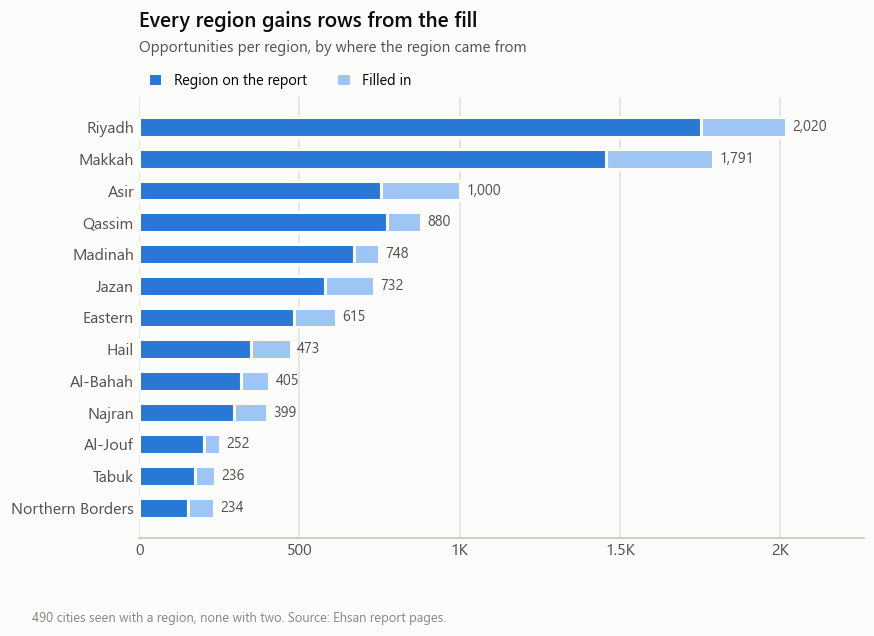

In [7]:
known = opp.dropna(subset=["region", "city_key"])
regions_per_city = known.groupby("city_key").region.nunique()
assert (regions_per_city == 1).all(), regions_per_city[regions_per_city > 1]

city_region = (known.groupby("city_key")
               .agg(region=("region", "first"), city_example=("city", "first"),
                    n_opportunities=("uid", "size"))
               .reset_index())
city_region.to_csv(CLEAN / "city_region.csv", index=False, encoding="utf-8-sig")

no_region = opp.region.isna()

def fill(source):
    """Fill still-missing regions from a Series of regions; return how many were filled."""
    missing = opp.region.isna()
    opp.loc[missing, "region"] = source[missing]
    return (missing & opp.region.notna()).sum()

by_city = fill(opp.city_key.map(city_region.set_index("city_key").region))

partner_regions = opp.dropna(subset=["region"]).groupby("partner_key").region.agg(["nunique", "first"])
one_region = partner_regions.loc[partner_regions["nunique"] == 1, "first"]
by_partner = fill(opp.partner_key.map(one_region))

manual = pd.read_csv(ROOT / "validation/manual_regions.csv").set_index("uid").region_ar
by_hand = fill(opp.uid.map(manual))

opp["region_filled"] = no_region & opp.region.notna()
log("fill region from city", by_city, f"lookup of {len(city_region)} cities, no conflicts")
log("fill region from association", by_partner, "association's other opportunities all in one region")
log("fill region by hand", by_hand, "validation/manual_regions.csv")
log("region still unknown", opp.region.isna().sum(), "no city and no association on the page; kept, excluded from regional figures")

REGION_EN = {
    "منطقة الرياض": "Riyadh", "منطقة مكة المكرمة": "Makkah", "المنطقة الشرقية": "Eastern",
    "منطقة المدينة المنورة": "Madinah", "منطقة القصيم": "Qassim", "منطقة عسير": "Asir",
    "منطقة جازان": "Jazan", "منطقة تبوك": "Tabuk", "منطقة حائل": "Hail",
    "منطقة الحدود الشمالية": "Northern Borders", "منطقة نجران": "Najran",
    "منطقة الباحة": "Al-Bahah", "منطقة الجوف": "Al-Jouf",
}
assert set(opp.region.dropna()) <= set(REGION_EN), set(opp.region.dropna()) - set(REGION_EN)
opp["region_en"] = opp.region.map(REGION_EN)

by_region = (opp.dropna(subset=["region_en"])
             .groupby("region_en").region_filled.agg(filled="sum", total="size")
             .assign(report=lambda t: t.total - t.filled)
             .sort_values("total", ascending=False))
fig, ax = plt.subplots(figsize=(8.5, 5.2))
viz.hbar_stack(ax, by_region.index, {"Region on the report": by_region.report,
                                     "Filled in": by_region.filled},
               colors=[viz.BLUE, viz.SEQ[1]], total_fmt=lambda v: f"{v:,.0f}")
viz.title(ax, "Every region gains rows from the fill", "Opportunities per region, by where the region came from")
viz.note(fig, f"{len(city_region)} cities seen with a region, none with two. Source: Ehsan report pages.")
viz.save(fig, "1_3_region_fill")
plt.show()

viz.takeaway(f"<b>{by_city:,}</b> regions filled in from the city, with no conflicts, <b>{by_partner}</b> from the "
             f"association and <b>{by_hand}</b> by hand. "
             f"Only <b>{opp.region.isna().sum()}</b> opportunities ({opp.region.isna().mean():.1%}) remain without a region.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">1.4</span>One column for money, one for beneficiaries

Completed opportunities report the **total raised**, which equals their target. Open ones report their **target**. Both are merged into `amount_sar`, and the two beneficiary fields are merged into `beneficiaries` the same way. `beneficiary_type` is renamed to `beneficiary_nationality`, because that is all it records (citizens, residents, or both).

In [8]:
opp["amount_sar"] = opp.total.where(opp.status == "completed", opp.target)
opp["beneficiaries"] = opp.beneficiaries.fillna(opp.beneficiaries_target)
opp = opp.rename(columns={"beneficiary_type": "beneficiary_nationality"})

no_amount = opp.amount_sar.isna()
log("amount unknown", no_amount.sum(), "report page returned a server error; kept, excluded from money totals")
viz.takeaway(f"The amount is known for <b>{1 - no_amount.mean():.2%}</b> of opportunities. "
             f"Together they raised <b>SAR {viz.compact(opp.loc[opp.status == 'completed', 'amount_sar'].sum())}</b>.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">1.5</span>How long did funding take?

`days_to_fund` = completion date − publish date. A handful of opportunities show a completion date **before** their publish date. They are mosque cases from mid-2023 and a few housing cases, most likely re-published after being funded. Their real publish date is unknown, so their `days_to_fund` is left empty instead of guessed.

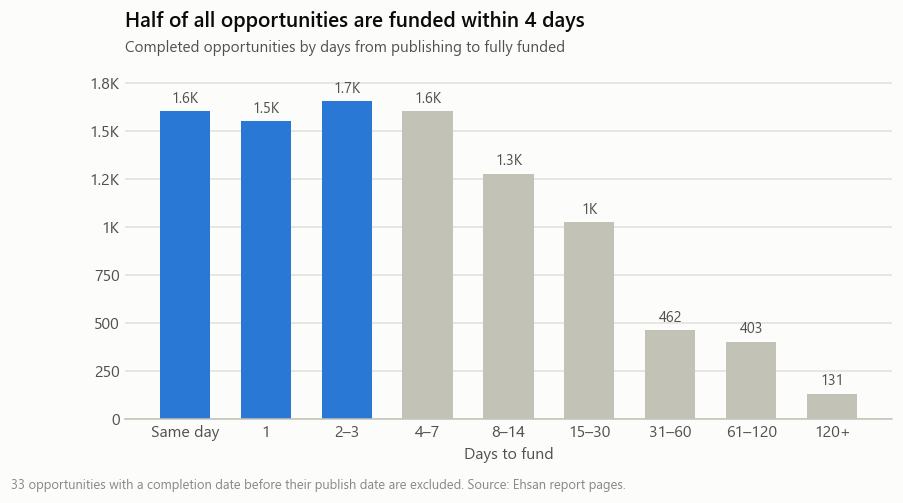

In [9]:
for col in ["publish_date", "completed_date"]:
    opp[col] = pd.to_datetime(opp[col], errors="coerce")
opp["days_to_fund"] = (opp.completed_date - opp.publish_date).dt.days
impossible = opp.days_to_fund.lt(0)
log("impossible dates", impossible.sum(), "completed before published; days_to_fund left empty")
opp.loc[impossible, "days_to_fund"] = np.nan

bins = [-1, 0, 1, 3, 7, 14, 30, 60, 120, np.inf]
names = ["Same day", "1", "2–3", "4–7", "8–14", "15–30", "31–60", "61–120", "120+"]
dist = pd.cut(opp.days_to_fund, bins, labels=names).value_counts().reindex(names)

d = opp.days_to_fund.dropna()
fig, ax = plt.subplots(figsize=(9, 4.2))
viz.vbar(ax, names, dist.values, highlight=["Same day", "1", "2–3"])
viz.title(ax, f"Half of all opportunities are funded within {d.median():.0f} days",
          "Completed opportunities by days from publishing to fully funded")
ax.set_xlabel("Days to fund")
viz.note(fig, f"{impossible.sum()} opportunities with a completion date before their publish date are excluded. Source: Ehsan report pages.")
viz.save(fig, "1_5_days_to_fund")
plt.show()

viz.takeaway(f"<b>{(d == 0).mean():.0%}</b> are funded the same day they are published, and half within "
             f"<b>{d.median():.0f}</b> days. The interesting cases are the slow tail: <b>{(d > 30).mean():.0%}</b> take more than a month.")

**Ehsan's first months.** Ehsan opened in early 2021. In its first six months donors were still discovering the platform, and very few opportunities were funded quickly. These opportunities say little about how donors respond today, so they are marked as the **launch period** (published before 1 August 2021). They stay in every figure about **what was posted**, but are left out of every comparison of **speed**.

In [10]:
LAUNCH_END = pd.Timestamp("2021-08-01")
opp["launch_period"] = opp.publish_date < LAUNCH_END
first_year = opp[(opp.status == "completed") & (opp.publish_date < "2022-01-01")]
by_month = (first_year.groupby(first_year.publish_date.dt.strftime("%Y-%m"))
            .agg(n=("uid", "size"), week=("days_to_fund", lambda s: (s.dropna() <= 7).mean()),
                 days=("days_to_fund", "median"))
            .reset_index())
by_month.columns = ["Published", "Opportunities", "Funded within a week", "Median days"]
display(viz.table(by_month, ints=["Opportunities", "Median days"], pct=["Funded within a week"],
                  caption="Ehsan's first year, by month of publishing"))
log("launch period", opp.launch_period.sum(), "published before 1 Aug 2021; kept, left out of speed comparisons")

after = opp.loc[(opp.status == "completed") & ~opp.launch_period, "days_to_fund"].dropna()
launch = opp.loc[opp.launch_period, "days_to_fund"].dropna()
viz.takeaway(f"Before August 2021 only <b>{(launch <= 7).mean():.0%}</b> of opportunities were funded within a week "
             f"(median {launch.median():.0f} days); from August 2021 on, <b>{(after <= 7).mean():.0%}</b> were "
             f"(median {after.median():.0f} days). The <b>{opp.launch_period.sum():,}</b> launch-period opportunities "
             "are kept but left out of speed comparisons.")

Published,Opportunities,Funded within a week,Median days
2021-02,20,0%,75
2021-03,39,10%,46
2021-04,312,4%,91
2021-05,174,45%,12
2021-06,93,51%,7
2021-07,154,34%,18
2021-08,114,87%,3
2021-09,126,88%,2
2021-10,114,80%,3
2021-11,116,80%,2


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">1.6</span>Cause and target group from titles

Ehsan gives the cause only for the 29 open projects; the 7,400 completed ones have none, and nothing says *who* a project helps beyond citizens or residents. Both can be read from the title, because titles are very standardised. The rules live in `labels.py` as two short, ordered keyword lists that anyone can read:

- **Cause = what is provided**, using Ehsan's own project types: food or water → Feeding, operations or medicine → Health, rent or repairs → Housing, Quran or Umrah → Religious, and so on. Concrete goods are checked first, so "meals for university students" is Feeding.
- **Target group = who receives it**: orphans, patients, widows, students, pilgrims, families in need… "General public" when the title names no group.

The labels of 100 randomly drawn projects were checked by hand (`validation/title_labels_check.csv`). The accuracy below is for the rules **as they were before** that check; the disagreements then led to four small rule fixes, noted in `labels.py`.

Opportunities from Ehsan's mosque-care section keep their own cause, **Mosques** (target group Pilgrims & worshippers), and those from the housing section are **Housing** / Families in need, by definition of their sections.

In [11]:
import labels

proj = opp.section == "projects"
lab = labels.label_titles(opp.loc[proj, "title_ar"])
opp["cause_source"] = np.where(opp.cause.notna(), "Ehsan listing", None)

# Check 1: on the open projects, Ehsan's own cause is known.
open_proj = proj & (opp.status == "active")
agree = (lab.loc[open_proj[proj].values, "cause"].values == opp.loc[open_proj, "cause"].values)

opp.loc[proj & opp.cause.isna(), "cause_source"] = "title rules"
opp.loc[proj & opp.cause.isna(), "cause"] = lab.cause
opp.loc[proj, "target_group"] = lab.target_group
opp.loc[opp.section == "mosques", "target_group"] = "Pilgrims & worshippers"
opp.loc[opp.section == "housing", "target_group"] = "Families in need"
log("cause from title", (opp.cause_source == "title rules").sum(), "labels.py rules; 'Other' when no rule matches")

# Check 2: a random sample checked by hand (validation/title_labels_check.csv).
check = pd.read_csv(ROOT / "validation/title_labels_check.csv")
done = check.cause_ok.notna() & check.target_group_ok.notna()
rows = [("Matches Ehsan's own cause on the open projects", f"{agree.sum()} / {len(agree)}"),
        ("Completed projects with no matching rule ('Other')",
         f"{(opp.cause == 'Other').sum()} of {(opp.cause_source == 'title rules').sum():,}")]
if done.sum() > 0:
    rows += [(f"Cause correct, hand check of {done.sum()} random projects", f"{check.loc[done, 'cause_ok'].mean():.0%}"),
             ("Target group correct, same check", f"{check.loc[done, 'target_group_ok'].mean():.0%}"),
             ("Rules fixed after the check", "4 (see labels.py comments)")]
else:
    rows += [("Hand check of 100 random projects", "pending")]
display(viz.table(pd.DataFrame(rows, columns=["Check", "Result"]), caption="How well the title rules work"))

viz.takeaway(f"The rules agree with Ehsan on <b>{agree.sum()} of {len(agree)}</b> open projects and leave only "
             f"<b>{(opp.cause == 'Other').mean():.1%}</b> of opportunities unlabelled.")

Check,Result
Matches Ehsan's own cause on the open projects,29 / 29
Completed projects with no matching rule ('Other'),"37 of 7,425"
"Cause correct, hand check of 100 random projects",97%
"Target group correct, same check",98%
Rules fixed after the check,4 (see labels.py comments)


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">1.7</span>Duplicates

Every opportunity has its own ID, so exact duplicate rows cannot occur. The real risk is the **same opportunity posted twice** under two IDs. Opportunities that share title, city, association, amount, publish date and completion date are flagged and reviewed case by case.

In [12]:
DUP_KEY = ["title_ar", "city", "partner_name", "amount_sar", "publish_date", "completed_date"]
assert opp.uid.is_unique
dups = opp[opp.title_ar.notna() & opp.duplicated(DUP_KEY, keep=False)].sort_values(DUP_KEY + ["uid"])
log("possible duplicates", len(dups), f"{dups.groupby(DUP_KEY).ngroups} identical pairs; kept, each copy was funded separately")
show = dups[["uid", "title_ar", "city", "amount_sar", "publish_date"]].copy()
show["publish_date"] = show.publish_date.dt.date
show["Decision"] = "kept"
display(viz.table(show.rename(columns={"uid": "ID", "title_ar": "Title", "city": "City",
                                       "amount_sar": "Amount (SAR)", "publish_date": "Published"}),
                  ints=["Amount (SAR)"], caption="Look identical, but each was funded: all kept"))
viz.takeaway(f"Only <b>{dups.groupby(DUP_KEY).ngroups}</b> pairs look identical, each with close IDs and published the same day. "
             "Both copies in every pair were fully funded, so they are most likely two separate batches (for example two "
             "lots of food baskets). Removing one would undercount money that was really raised, so <b>all are kept</b>.")

ID,Title,City,Amount (SAR),Published,Decision
Project-572,سلال غذائية للأسر المحتاجة,جدة,"100,000",2021-05-03,kept
Project-574,سلال غذائية للأسر المحتاجة,جدة,"100,000",2021-05-03,kept
Project-12230,كفالة الأيتام,نجران,"120,000",2022-02-04,kept
Project-12232,كفالة الأيتام,نجران,"120,000",2022-02-04,kept
Project-47431,وجبات الطعام للحجاج,مكة المكرمة,"500,000",2024-06-15,kept
Project-47440,وجبات الطعام للحجاج,مكة المكرمة,"500,000",2024-06-15,kept


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">1.8</span>Rules every row must pass

Simple facts that must hold for any opportunity. Each rule is checked on every row, and the table shows how many break it and how they were handled. Nothing is deleted: a broken value is emptied or the row is left out of the one calculation it would distort.

In [13]:
EHSAN_START, SNAPSHOT = pd.Timestamp("2021-01-01"), pd.Timestamp("2026-10-23")
is_open = opp.status == "active"
rules = [
    ("Published within Ehsan's lifetime (2021 to collection day)",
     opp.publish_date.notna() & ~opp.publish_date.between(EHSAN_START, SNAPSHOT), "none found"),
    ("Completed on or before collection day", opp.completed_date > SNAPSHOT, "none found"),
    ("Completed on or after publishing", impossible, "days to fund left empty (1.5)"),
    ("Amount above zero", opp.amount_sar <= 0, "none found"),
    ("Beneficiaries above zero", opp.beneficiaries <= 0, "set to empty"),
    ("Open projects: collected no more than the target", is_open & (opp.collected > opp.target),
     "kept; amount uses the target"),
    ("Visits not negative", opp.visits < 0, "none found"),
    ("Region known", opp.region.isna(), "kept; left out of regional figures (1.3)"),
]
opp.loc[opp.beneficiaries <= 0, "beneficiaries"] = np.nan
ALREADY_LOGGED = {"Completed on or after publishing", "Region known"}   # logged in 1.5 and 1.3
for name, broken, action in rules:
    if broken.sum() and name not in ALREADY_LOGGED:
        log(f"rule: {name.lower()}", broken.sum(), action)
rule_table = pd.DataFrame([(n, int(b.sum()), a if b.sum() else "–") for n, b, a in rules],
                          columns=["Rule", "Rows breaking it", "How it was handled"])
display(viz.table(rule_table, ints=["Rows breaking it"]))
worst = max(int(b.sum()) for _, b, _ in rules)
viz.takeaway(f"No rule is broken by more than <b>{worst}</b> opportunities ({worst / len(opp):.1%}), and every "
             "break is handled without deleting an opportunity.")

Rule,Rows breaking it,How it was handled
Published within Ehsan's lifetime (2021 to collection day),0,–
Completed on or before collection day,0,–
Completed on or after publishing,33,days to fund left empty (1.5)
Amount above zero,0,–
Beneficiaries above zero,2,set to empty
Open projects: collected no more than the target,5,kept; amount uses the target
Visits not negative,0,–
Region known,3,kept; left out of regional figures (1.3)


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">1.9</span>Unusual values

Very large or very small values are not automatically errors. For each number, the typical value (median) is compared with the extremes, and rows far outside the usual range are counted (more than three interquartile ranges above the upper quartile).

In [14]:
def extremes(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    return {"Median": s.median(), "99th percentile": s.quantile(.99), "Largest": s.max(),
            "Far above usual": int((s > q3 + 3 * (q3 - q1)).sum())}

done = opp.status == "completed"
unusual = pd.DataFrame({
    "Amount (SAR)": extremes(opp.amount_sar),
    "Beneficiaries": extremes(opp.beneficiaries),
    "Visits": extremes(opp.visits),
    "Days to fund": extremes(opp.loc[done, "days_to_fund"]),
}).T.reset_index().rename(columns={"index": "Value"})
unusual["Why they are kept"] = [
    "the largest are mosque-building projects (up to SAR 8.5M)",
    "mixes people supported with people reached (1M for water to pilgrims)",
    "popular Ramadan and Hajj campaigns",
    "a real slow tail: 9% take over a month, 5 took over a year",
]
display(viz.table(unusual, ints=["Median", "99th percentile", "Largest", "Far above usual"]))
viz.takeaway("The extremes are real projects, not typing errors, so they stay. But beneficiary counts measure "
             "different things for different causes, so later sections use <b>medians</b> and compare riyals per "
             "beneficiary only <b>within</b> a cause, never across causes.")

Value,Median,99th percentile,Largest,Far above usual,Why they are kept
Amount (SAR),"122,242","1,000,000","8,462,562",159,the largest are mosque-building projects (up to SAR 8.5M)
Beneficiaries,105,"250,000","1,090,909",958,mixes people supported with people reached (1M for water to pilgrims)
Visits,"5,530","77,127","686,735",270,popular Ramadan and Hajj campaigns
Days to fund,4,128,426,690,"a real slow tail: 9% take over a month, 5 took over a year"


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">1.10</span>Before and after

Three fields the analysis depends on are incomplete or missing in the raw data: the region, the cause and the target group. How much does cleaning fill in? ("Other" counts as missing.)

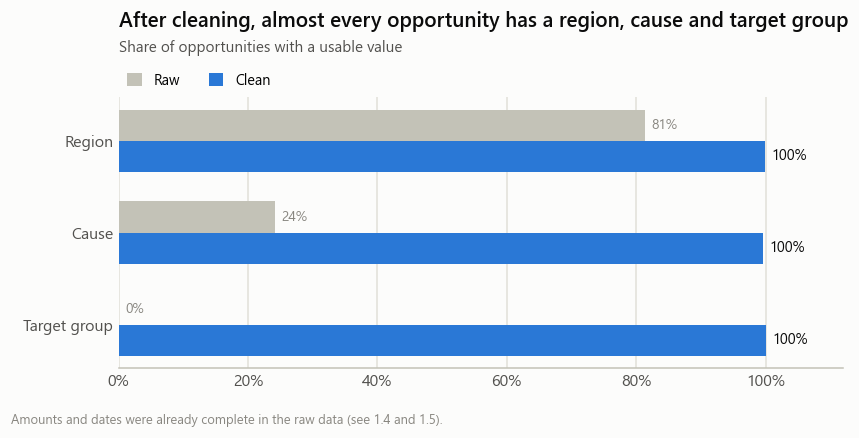

In [15]:
scope = raw
fields = {   # (share usable in the raw data, share after cleaning)
    "Region": (scope.region.notna().mean(), opp.region.notna().mean()),
    "Cause": (scope.category.isin(PROJECT_CAUSES + ["CompletedMosques", "CompletedHousing",
                                                    "Mosques", "HousingPlatform"]).mean(),
              opp.cause.ne("Other").mean()),
    "Target group": (0.0, opp.target_group.notna().mean()),
}
fig, ax = plt.subplots(figsize=(8.5, 3.2))
viz.hbar_pair(ax, list(fields), [v[0] for v in fields.values()], [v[1] for v in fields.values()])
viz.title(ax, "After cleaning, almost every opportunity has a region, cause and target group",
          "Share of opportunities with a usable value")
viz.note(fig, "Amounts and dates were already complete in the raw data (see 1.4 and 1.5).")
viz.save(fig, "1_7_completeness")
plt.show()

In [16]:
CLEAN_COLS = ["uid", "section", "status", "cause", "target_group", "title_ar", "region", "region_en",
              "region_filled", "city", "partner_name", "beneficiaries", "beneficiary_nationality",
              "amount_sar", "visits", "publish_date", "completed_date", "days_to_fund", "launch_period"]
display(viz.table(profile(opp, CLEAN_COLS), pct=["Filled"], ints=["Distinct"],
                  caption="Clean columns (opportunities_clean.csv)"))

Column,Type,Filled,Distinct,Example
uid,text,100%,"9,788",Project-82979
section,text,100%,3,projects
status,text,100%,2,active
cause,text,100%,9,Education
target_group,text,100%,12,Students
title_ar,text,94%,"3,286",الكفالة التعليمية للطلاب الجامعيين
region,text,100%,13,منطقة مكة المكرمة
region_en,text,100%,13,Makkah
region_filled,yes/no,100%,2,True
city,text,100%,510,الطائف


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">1.11</span>Save the clean table and the cleaning log

The raw file keeps every original column. The clean file keeps only what the analysis uses. Both are described in `data_clean/DATA_DICTIONARY.md`.

In [17]:
opp_clean = opp[CLEAN_COLS].copy()
opp_clean.to_csv(CLEAN / "opportunities_clean.csv", index=False, encoding="utf-8-sig")

log_df = pd.DataFrame(cleaning_log)
log_df.to_csv(CLEAN / "cleaning_log.csv", index=False, encoding="utf-8-sig")
log_df.columns = ["Step", "Rows affected", "Note"]
display(viz.table(log_df, ints=["Rows affected"], caption="Cleaning log"))
print(f"opportunities_clean.csv: {opp_clean.shape[0]:,} rows × {opp_clean.shape[1]} columns")

Step,Rows affected,Note
merge city spellings,18,3 cities had more than one spelling
check association spellings,0,"1,785 associations, 0 with more than one spelling"
fill region from city,"1,804","lookup of 490 cities, no conflicts"
fill region from association,11,association's other opportunities all in one region
fill region by hand,8,validation/manual_regions.csv
region still unknown,3,"no city and no association on the page; kept, excluded from regional figures"
amount unknown,3,"report page returned a server error; kept, excluded from money totals"
impossible dates,33,completed before published; days_to_fund left empty
launch period,792,"published before 1 Aug 2021; kept, left out of speed comparisons"
cause from title,"7,425",labels.py rules; 'Other' when no rule matches


opportunities_clean.csv: 9,788 rows × 19 columns


## <span style="display:inline-block;min-width:1.8em;padding:.1em .4em;margin-right:.5em;border-radius:.4em;background:#3987e5;color:#fff;text-align:center;font-weight:600">2</span>Who gets funded
<div style="border-bottom:1px solid rgba(127,127,127,.35);margin:-4px 0 14px"></div>

Every completed opportunity in the archive was funded in full, so the money it raised equals the amount its association **asked for**. Totals therefore describe **what associations post**, not what donors prefer: a cause with many large postings has a large total. Donor response is compared **per opportunity**, by how many days it took to be fully funded, which does not grow with the number of postings.

Each part below shows both views: what was posted, and how quickly donors funded it.

In [18]:
done = opp_clean[opp_clean.status == "completed"].copy()
done["publish_date"] = pd.to_datetime(done.publish_date)
done["completed_date"] = pd.to_datetime(done.completed_date)
# Speed is compared only after the launch period (1.5); those rows still count in what was posted.
done["days_to_fund"] = done.days_to_fund.where(~done.launch_period)
total_raised = done.amount_sar.sum()
print(f"{len(done):,} completed opportunities, SAR {viz.compact(total_raised)} posted and raised; "
      f"{done.days_to_fund.notna().sum():,} used for speed")

9,737 completed opportunities, SAR 1.9B posted and raised; 8,909 used for speed


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">2.1</span>What do associations post?

The total value of completed opportunities per cause, with the number of opportunities behind it. This shows where associations on Ehsan put their effort.

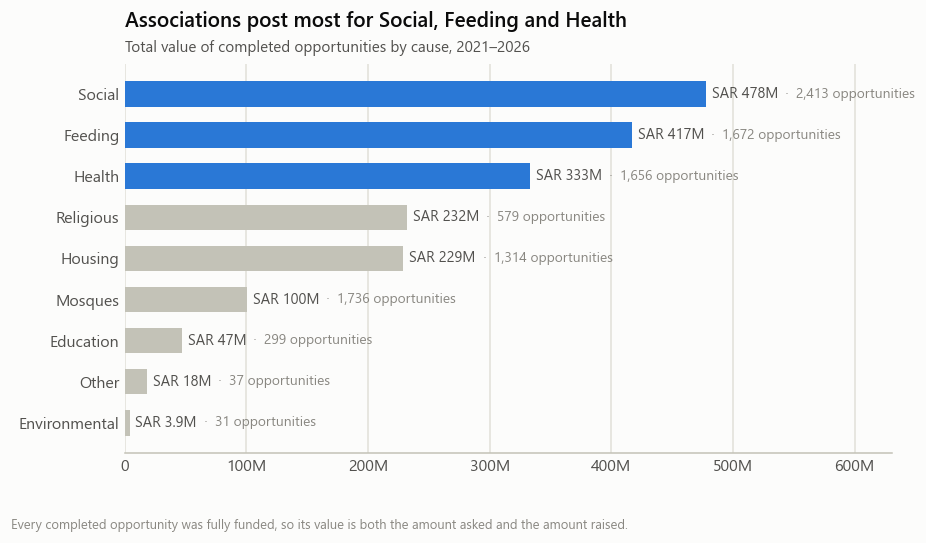

In [19]:
by_cause = (done.groupby("cause")
            .agg(raised=("amount_sar", "sum"), n=("uid", "size"), typical=("amount_sar", "median"),
                 days=("days_to_fund", "median"), slow=("days_to_fund", lambda s: (s.dropna() > 30).mean()))
            .sort_values("raised", ascending=False))
by_cause["share"] = by_cause.raised / total_raised
top3 = by_cause.index[:3]

fig, ax = plt.subplots(figsize=(9, 4.6))
viz.hbar(ax, by_cause.index, by_cause.raised, highlight=list(top3),
         fmt=lambda v: f"SAR {viz.compact(v)}", extra=[f"{n:,} opportunities" for n in by_cause.n])
viz.title(ax, f"Associations post most for {top3[0]}, {top3[1]} and {top3[2]}",
          "Total value of completed opportunities by cause, 2021–2026")
viz.note(fig, "Every completed opportunity was fully funded, so its value is both the amount asked and the amount raised.")
viz.save(fig, "2_1_cause_posted")
plt.show()

viz.takeaway(f"Three causes make up <b>{by_cause.share[:3].sum():.0%}</b> of the SAR {viz.compact(total_raised)} posted. "
             f"Education is <b>{by_cause.share.get('Education', 0):.0%}</b>, and only {by_cause.n.get('Environmental', 0)} "
             "environmental projects were posted in five years. These totals reflect what associations ask for, not donor preference.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">2.2</span>How fast do donors fund each cause?

The fair comparison of donor response: the **median days** from publishing to fully funded, per opportunity. Larger opportunities naturally take longer, so the table below repeats the comparison within four size bands of equal count.

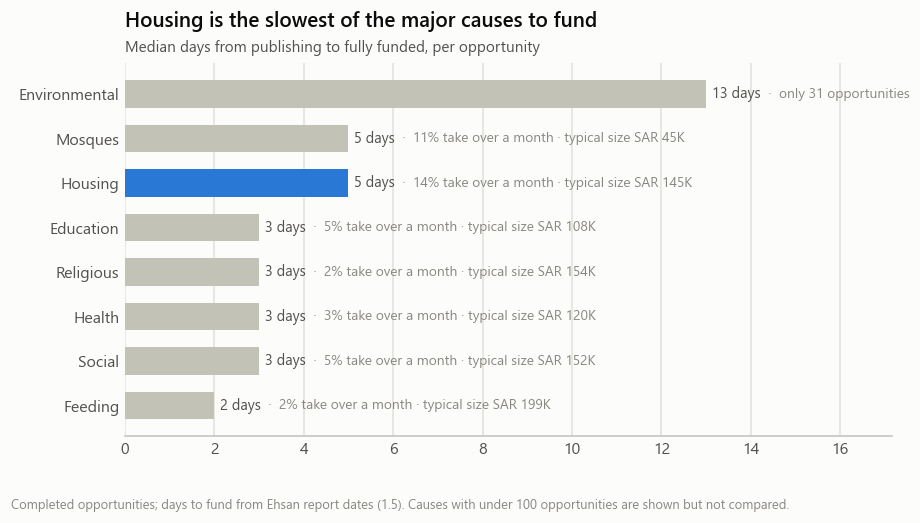

Cause,Small (SAR 534–72K),Mid-small (SAR 72K–122K),Mid-large (SAR 122K–237K),Large (SAR 238K–8.5M)
Feeding,1,2,3,2
Social,2,3,4,4
Health,1,3,4,7
Religious,1,2,4,4
Education,1,4,4,8
Housing,1,5,6,7
Mosques,4,6,7,12
Environmental,3,11,17,22


In [20]:
speed = by_cause.drop(index=["Other"], errors="ignore").sort_values("days")
major = speed[speed.n >= 100]          # small causes are too noisy to headline
slowest = major.days.idxmax()

fig, ax = plt.subplots(figsize=(9, 4.4))
viz.hbar(ax, speed.index[::-1], speed.days[::-1], highlight=[slowest],
         fmt=lambda v: f"{v:.0f} days",
         extra=[(f"only {n} opportunities" if n < 100 else
                 f"{s:.0%} take over a month · typical size SAR {viz.compact(t)}")
                for s, t, n in zip(speed.slow[::-1], speed.typical[::-1], speed.n[::-1])])
viz.title(ax, f"{slowest} is the slowest of the major causes to fund",
          "Median days from publishing to fully funded, per opportunity")
viz.note(fig, "Completed opportunities; days to fund from Ehsan report dates (1.5). Causes with under 100 opportunities are shown but not compared.")
viz.save(fig, "2_2_cause_speed")
plt.show()

done["size_band"] = pd.qcut(done.amount_sar, 4, labels=["Small", "Mid-small", "Mid-large", "Large"])
bands = done.groupby("size_band", observed=True).amount_sar.agg(["min", "max"])
by_size = (done[done.cause.isin(speed.index)]
           .pivot_table(index="cause", columns="size_band", values="days_to_fund", aggfunc="median", observed=True)
           .reindex(speed.index))
by_size.columns = [f"{b} (SAR {viz.compact(bands.loc[b, 'min'])}–{viz.compact(bands.loc[b, 'max'])})" for b in by_size.columns]
display(viz.table(by_size.reset_index().rename(columns={"cause": "Cause"}), ints=list(by_size.columns),
                  caption="Median days to fund, within size bands"))

viz.takeaway(f"Feeding opportunities fund fastest (<b>{speed.loc['Feeding', 'days']:.0f} days</b>). "
             f"{slowest} takes <b>{speed.loc[slowest, 'days']:.0f} days</b>, and {speed.loc[slowest, 'slow']:.0%} of its "
             "opportunities take over a month. The gap is not a size effect: Housing is slower than Feeding and Health "
             "in every size band. (Environmental looks slow, but with only 31 opportunities it is too small to compare.)")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">2.3</span>Who are the opportunities for?

The same two views by target group (1.6): what was posted for each group, and how quickly it was funded. "General public" covers projects that name no group, such as water for remote villages, and is shown in gray.

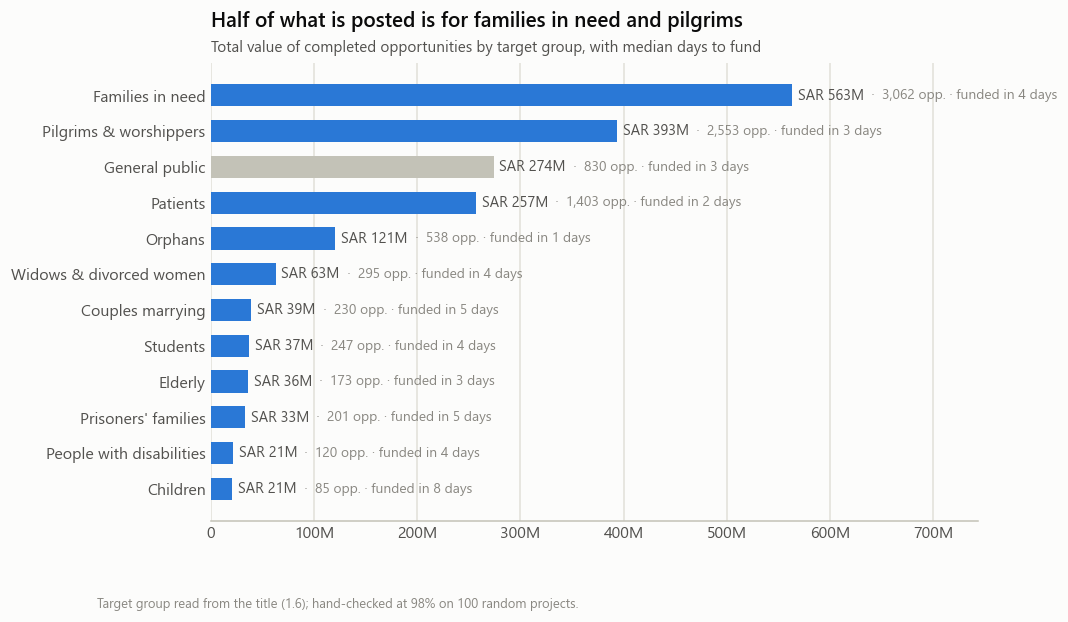

In [21]:
by_group = (done.groupby("target_group")
            .agg(raised=("amount_sar", "sum"), n=("uid", "size"), days=("days_to_fund", "median"),
                 slow=("days_to_fund", lambda s: (s.dropna() > 30).mean()))
            .sort_values("raised", ascending=False))
by_group["share"] = by_group.raised / total_raised
named = [g for g in by_group.index if g != "General public"]

fig, ax = plt.subplots(figsize=(9, 5.4))
viz.hbar(ax, by_group.index, by_group.raised, highlight=named,
         fmt=lambda v: f"SAR {viz.compact(v)}",
         extra=[f"{n:,} opp. · funded in {d:.0f} days" for n, d in zip(by_group.n, by_group.days)])
viz.title(ax, "Half of what is posted is for families in need and pilgrims",
          "Total value of completed opportunities by target group, with median days to fund")
viz.note(fig, "Target group read from the title (1.6); hand-checked at 98% on 100 random projects.")
viz.save(fig, "2_3_target_group")
plt.show()

slow_g = by_group.drop(index="General public").days.idxmax()
small = by_group.loc[["Elderly", "People with disabilities", "Children"]]
viz.takeaway(f"<b>Families in need</b> ({by_group.share['Families in need']:.0%}) and <b>pilgrims and worshippers</b> "
             f"({by_group.share['Pilgrims & worshippers']:.0%}) account for half of all postings, while the elderly, people "
             f"with disabilities and children together account for <b>{small.share.sum():.0%}</b>. Opportunities for "
             f"<b>{slow_g.lower()}</b> are also the slowest to fund ({by_group.loc[slow_g, 'days']:.0f} days, "
             f"{by_group.loc[slow_g, 'slow']:.0%} over a month): few are posted, and donors take longest to fill them.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">2.4</span>What does it cost to help one person?

Riyals per beneficiary, for each opportunity, summarised by the median within each cause. Beneficiary counts mean different things for different causes (people *supported* by a sponsorship, people *reached* by a water project, see 1.9), so the comparison is meaningful **within** a cause and shows the order of magnitude **across** causes.

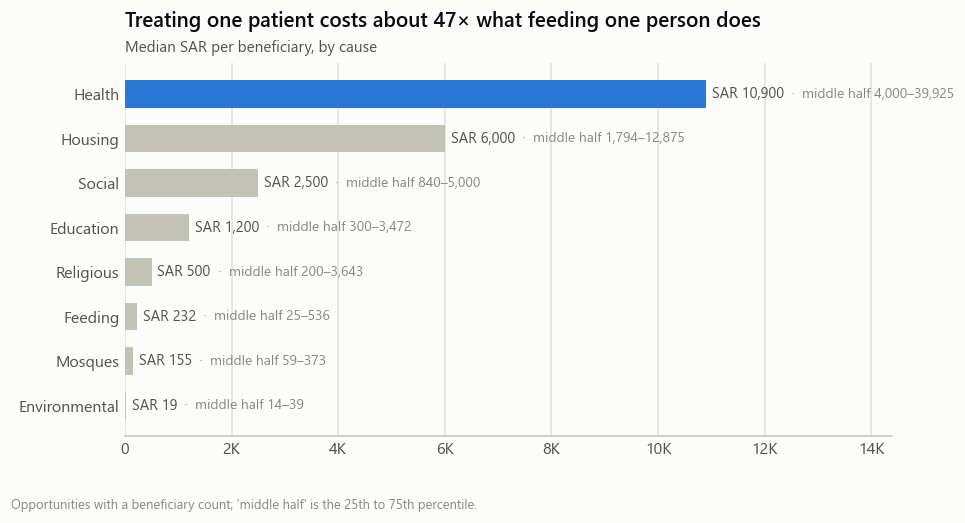

In [22]:
per_person = (done[done.beneficiaries > 0]
              .assign(sar_per_person=lambda t: t.amount_sar / t.beneficiaries)
              .groupby("cause").sar_per_person
              .agg(median="median", q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75), n="size")
              .drop(index=["Other"], errors="ignore")
              .sort_values("median", ascending=False))

fig, ax = plt.subplots(figsize=(9, 4.4))
viz.hbar(ax, per_person.index, per_person["median"], highlight=["Health"],
         fmt=lambda v: f"SAR {v:,.0f}",
         extra=[f"middle half {a:,.0f}–{b:,.0f}" for a, b in zip(per_person.q1, per_person.q3)])
ratio = per_person.loc["Health", "median"] / per_person.loc["Feeding", "median"]
viz.title(ax, f"Treating one patient costs about {ratio:.0f}× what feeding one person does",
          "Median SAR per beneficiary, by cause")
viz.note(fig, "Opportunities with a beneficiary count; 'middle half' is the 25th to 75th percentile.")
viz.save(fig, "2_4_cost_per_person")
plt.show()

viz.takeaway(f"The median health opportunity raises <b>SAR {per_person.loc['Health', 'median']:,.0f}</b> per patient, "
             f"housing <b>SAR {per_person.loc['Housing', 'median']:,.0f}</b> per beneficiary and feeding "
             f"<b>SAR {per_person.loc['Feeding', 'median']:,.0f}</b>. The same riyal reaches very different numbers of people "
             "depending on the cause, so totals say little about how many people were helped.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">2.5</span>How has posting changed over time?

Value posted per year, one small panel per cause on the same scale, by completion year. 2026 runs only to 23 October, so its point is drawn hollow. The mosque-care archive starts in 2023.

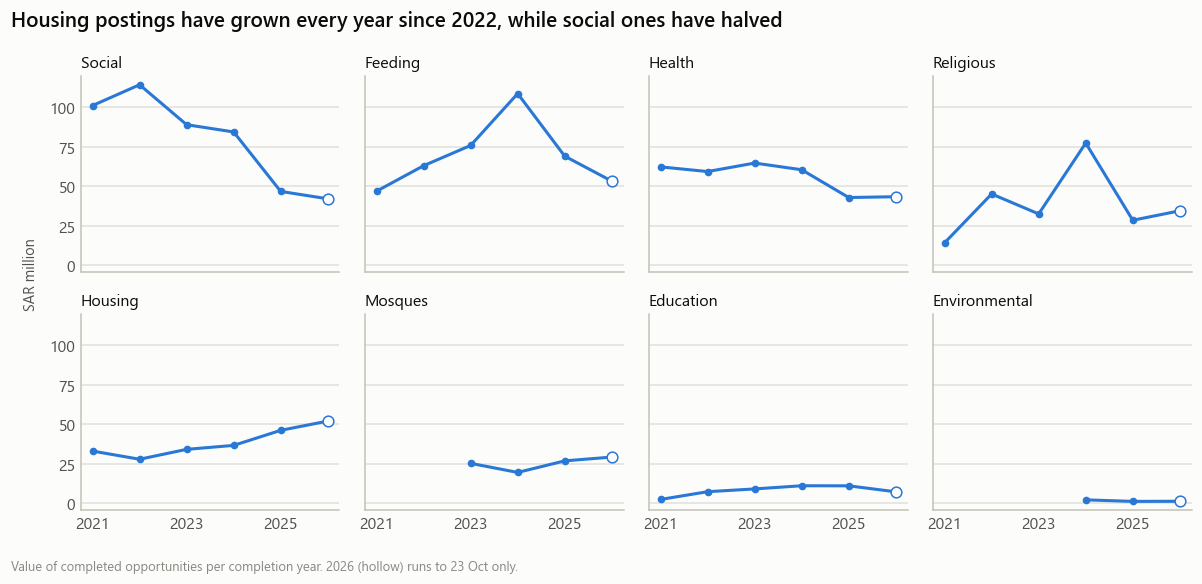

In [23]:
yearly = (done.assign(year=done.completed_date.dt.year)
          .groupby(["cause", "year"]).amount_sar.sum().div(1e6).unstack(0))
causes = [c for c in by_cause.index if c != "Other"]
fig, axes = plt.subplots(2, 4, figsize=(11, 5), sharex=True, sharey=True)
for ax, cause in zip(axes.flat, causes):
    s = yearly[cause].dropna()
    ax.plot(s.index, s.values, color=viz.BLUE, marker="o", markersize=4)
    if 2026 in s.index:   # partial year
        ax.plot([2026], [s[2026]], "o", markersize=7, markerfacecolor=viz.SURFACE, markeredgecolor=viz.BLUE)
    ax.set_title(cause, loc="left", fontsize=10.5, color=viz.INK)
    ax.grid(axis="x", visible=False)
    ax.set_xticks([2021, 2023, 2025])
for ax in axes.flat[len(causes):]:
    ax.set_visible(False)
fig.supylabel("SAR million", fontsize=9.5, color=viz.INK_2)
fig.suptitle("Housing postings have grown every year since 2022, while social ones have halved",
             x=0.01, ha="left", fontsize=13.5, fontweight="semibold", color=viz.INK)
fig.tight_layout()
viz.note(fig, "Value of completed opportunities per completion year. 2026 (hollow) runs to 23 Oct only.")
viz.save(fig, "2_5_trend")
plt.show()

viz.takeaway(f"Housing postings have grown every year since 2022, to <b>SAR {yearly.loc[2026, 'Housing']:.0f}M</b> in 2026 "
             f"(to October), while Social fell from <b>SAR {yearly.loc[2022, 'Social']:.0f}M</b> in 2022 to "
             f"<b>SAR {yearly.loc[2025, 'Social']:.0f}M</b> in 2025. Since housing is also the slowest major cause to fund "
             "(2.2), more of it is waiting on donors each year.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">2.6</span>How much Ehsan project activity reaches each region?

Each region's share of the value posted next to its share of the population (GASTAT Census 2022). This measures **coverage**: how much project activity on Ehsan reaches a region relative to how many people live there. It says nothing about donor generosity, and population is only a rough stand-in for need. Section 3 adds donor response and looks at each cause separately.

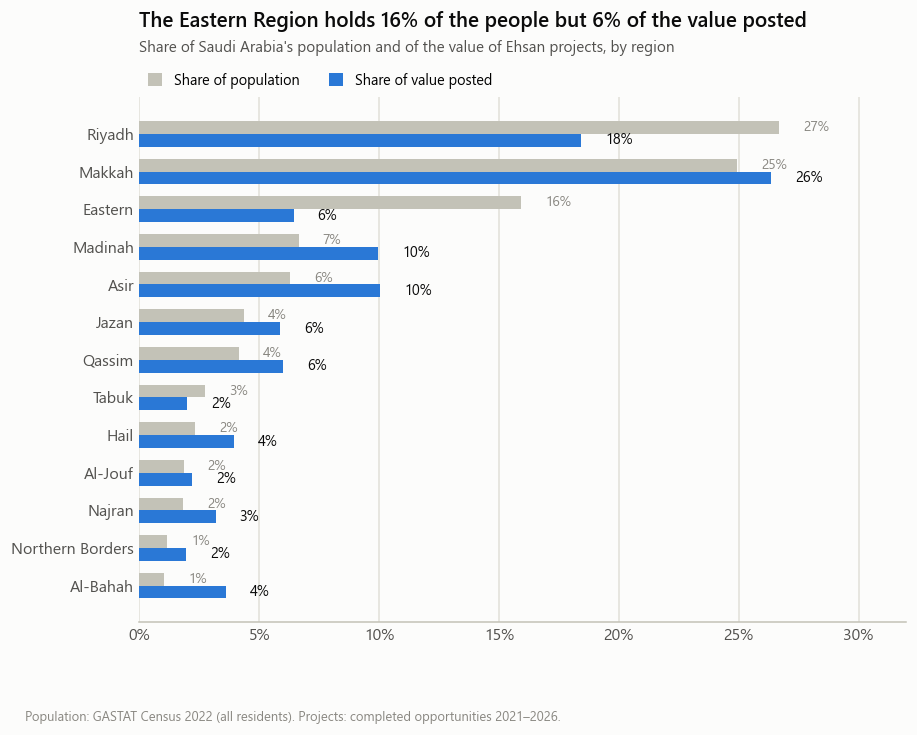

In [24]:
population = pd.read_csv(ROOT / "data_raw/gastat/census_2022_regions.csv")
population.to_csv(CLEAN / "population.csv", index=False, encoding="utf-8-sig")

regions = (done.dropna(subset=["region_en"]).groupby("region_en")
           .agg(raised=("amount_sar", "sum"), n=("uid", "size"))
           .join(population.set_index("region_en")[["total"]]))
regions["money_share"] = regions.raised / regions.raised.sum()
regions["people_share"] = regions.total / regions.total.sum()
regions["per_person"] = regions.raised / regions.total
regions["per_100k"] = regions.n / regions.total * 1e5
regions = regions.sort_values("people_share", ascending=False)

fig, ax = plt.subplots(figsize=(9, 6.2))
viz.hbar_pair(ax, regions.index, regions.people_share, regions.money_share,
              names=("Share of population", "Share of value posted"))
ax.set_xlim(0, 0.32)
viz.title(ax, "The Eastern Region holds 16% of the people but 6% of the value posted",
          "Share of Saudi Arabia's population and of the value of Ehsan projects, by region")
viz.note(fig, "Population: GASTAT Census 2022 (all residents). Projects: completed opportunities 2021–2026.")
viz.save(fig, "2_6_region_coverage")
plt.show()

lo, hi = regions.per_person.idxmin(), regions.per_person.idxmax()
viz.takeaway(f"Per resident, projects worth SAR {regions.per_person[lo]:.0f} were posted for <b>{lo}</b> and "
             f"SAR {regions.per_person[hi]:.0f} for <b>{hi}</b> ({regions.per_100k[lo]:.0f} vs {regions.per_100k[hi]:.0f} "
             "opportunities per 100,000 residents). Riyadh and Tabuk are also below their population share. This is a "
             "difference in what associations post there, not in how donors respond.")

## <span style="display:inline-block;min-width:1.8em;padding:.1em .4em;margin-right:.5em;border-radius:.4em;background:#3987e5;color:#fff;text-align:center;font-weight:600">3</span>The coverage gap
<div style="border-bottom:1px solid rgba(127,127,127,.35);margin:-4px 0 14px"></div>
Every **region × cause** pair (for example Jazan × Health) is measured on two fair scales:

- **Coverage**: value posted per resident, divided by the national rate for the **same cause**. 1.0 means the region gets exactly its population's share; 0.5 means half. Comparing within each cause keeps large causes from swamping small ones.
- **Donor response**: the share of the pair's opportunities **funded within a week**, compared with the same cause nationally, in percentage points. This is measured per opportunity, so it does not grow with the number of postings. Pairs with fewer than 20 completed opportunities are too small for a speed verdict. A difference of under **5 points** counts as the normal pace: for a typical pair (about 70 opportunities) the share funded within a week varies by roughly that much by chance alone.

Together they sort every pair into one of four situations:

| | Donors fund it at the **normal pace or faster** | Donors fund it **slower** (by 5+ points) |
|---|---|---|
| **Coverage below 1** | **Supply gap**: donors respond, but little is posted. Help associations there post more. | **Neglected**: little is posted and it funds slowly. Direct grants or matching funds here. |
| **Coverage above 1** | Well covered | **Saturated**: much is posted and donors are slow. Coordinate rather than add. |

Environmental and "Other" are left out: too few opportunities to split by region.

In [25]:
CAUSES = ["Social", "Feeding", "Health", "Religious", "Housing", "Mosques", "Education"]
MIN_N = 20   # completed opportunities needed for a speed verdict
TOL = 5      # points; smaller speed differences are within chance variation

base = done[done.region_en.notna() & done.cause.isin(CAUSES)]
pop = population.set_index("region_en")
national = base.groupby("cause").agg(value=("amount_sar", "sum"),
                                     week=("days_to_fund", lambda s: (s.dropna() <= 7).mean()))

gap = (base.groupby(["region_en", "cause"])
       .agg(n=("uid", "size"), value=("amount_sar", "sum"),
            week=("days_to_fund", lambda s: (s.dropna() <= 7).mean()),
            associations=("partner_name", "nunique"))
       .reset_index()
       .join(pop[["total", "saudi"]], on="region_en"))
gap["coverage"] = (gap.value / gap.total) / gap.cause.map(national.value / pop.total.sum())
gap["coverage_saudi"] = (gap.value / gap.saudi) / gap.cause.map(national.value / pop.saudi.sum())
gap["speed"] = (gap.week - gap.cause.map(national.week)) * 100          # percentage points
gap.loc[gap.n < MIN_N, "speed"] = np.nan
gap["associations_per_100k"] = gap.associations / gap.total * 1e5

def situation(row):
    if np.isnan(row.speed):
        return "Too few to judge"
    slow = row.speed < -TOL
    if row.coverage < 1:
        return "Neglected" if slow else "Supply gap"
    return "Saturated" if slow else "Well covered"
gap["situation"] = gap.apply(situation, axis=1)
gap.to_csv(ROOT / "outputs/coverage_gap.csv", index=False, encoding="utf-8-sig")
gap.situation.value_counts()

situation
Well covered        36
Supply gap          21
Saturated           15
Too few to judge    13
Neglected            6
Name: count, dtype: int64

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">3.1</span>Coverage: how much is posted, relative to population

Each cell is a region's coverage for one cause. Red cells get less than their population's share of what is posted nationally for that cause, blue cells more. Regions are ordered from lowest to highest overall coverage.

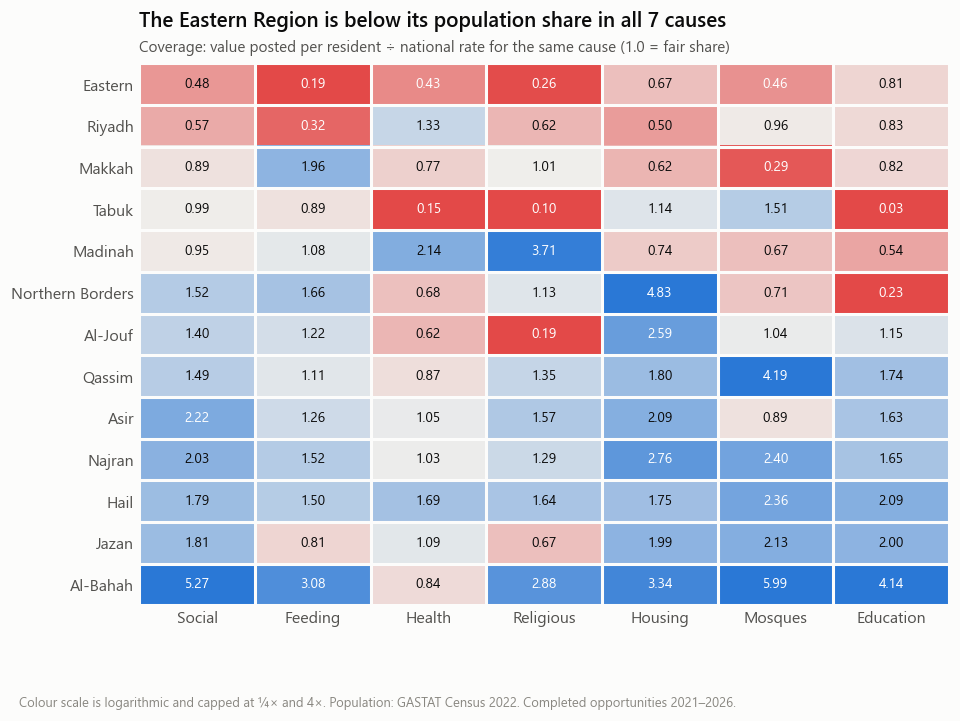

In [26]:
cov = gap.pivot(index="region_en", columns="cause", values="coverage")[CAUSES]
cov = cov.loc[cov.median(axis=1).sort_values().index]
below = (cov < 1).sum(axis=1)

fig, ax = plt.subplots(figsize=(9.5, 6.4))
viz.heat(ax, cov, center=1.0, log=True, low_is_bad=True, fmt=lambda v: f"{v:.2f}", limits=2)
viz.title(ax, f"The Eastern Region is below its population share in all {len(CAUSES)} causes",
          "Coverage: value posted per resident ÷ national rate for the same cause (1.0 = fair share)")
viz.note(fig, "Colour scale is logarithmic and capped at ¼× and 4×. Population: GASTAT Census 2022. Completed opportunities 2021–2026.")
viz.save(fig, "3_1_coverage")
plt.show()

full = below[below == len(CAUSES)].index.tolist()
viz.takeaway(f"<b>{', '.join(full)}</b> {'is' if len(full) == 1 else 'are'} below the fair share in every cause. "
             f"Riyadh is below in {below['Riyadh']} of {len(CAUSES)}, Tabuk in {below['Tabuk']}. At the other end, "
             "small regions such as Al-Bahah and Hail have several times their population share posted in most causes.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">3.2</span>Donor response: how fast it is funded

Each cell compares the share of a pair's opportunities funded within a week with the national share for the same cause, in percentage points. Red is slower than usual, blue faster. Blank cells have fewer than 20 completed opportunities.

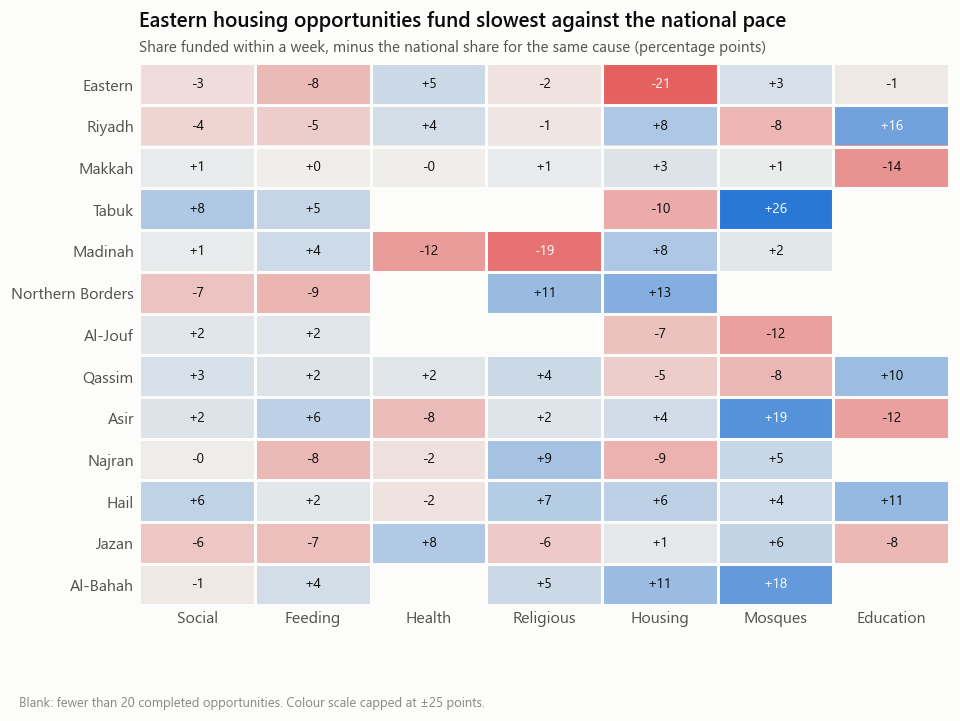

In [27]:
spd = gap.pivot(index="region_en", columns="cause", values="speed")[CAUSES].reindex(cov.index)
fig, ax = plt.subplots(figsize=(9.5, 6.4))
viz.heat(ax, spd, center=0, log=False, low_is_bad=True, fmt=lambda v: f"{v:+.0f}",
         mask=spd.isna(), limits=25)
worst = gap.dropna(subset=["speed"]).nsmallest(1, "speed").iloc[0]
viz.title(ax, f"{worst.region_en} {worst.cause.lower()} opportunities fund slowest against the national pace",
          "Share funded within a week, minus the national share for the same cause (percentage points)")
viz.note(fig, "Blank: fewer than 20 completed opportunities. Colour scale capped at ±25 points.")
viz.save(fig, "3_2_speed")
plt.show()

nat_week = national.week.loc[worst.cause]
viz.takeaway(f"In <b>{worst.region_en}</b>, only {worst.week:.0%} of {worst.cause.lower()} opportunities are funded "
             f"within a week, against {nat_week:.0%} nationally. Speed differences are smaller than coverage differences: "
             "donors respond fairly evenly across regions, so most of the gap comes from what is posted.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">3.3</span>Putting both together

Every pair with enough opportunities, placed by coverage (left = less posted than its population's share) and donor response (down = slower than usual). The lower-left quadrant is **neglected**, the upper-left a **supply gap**.

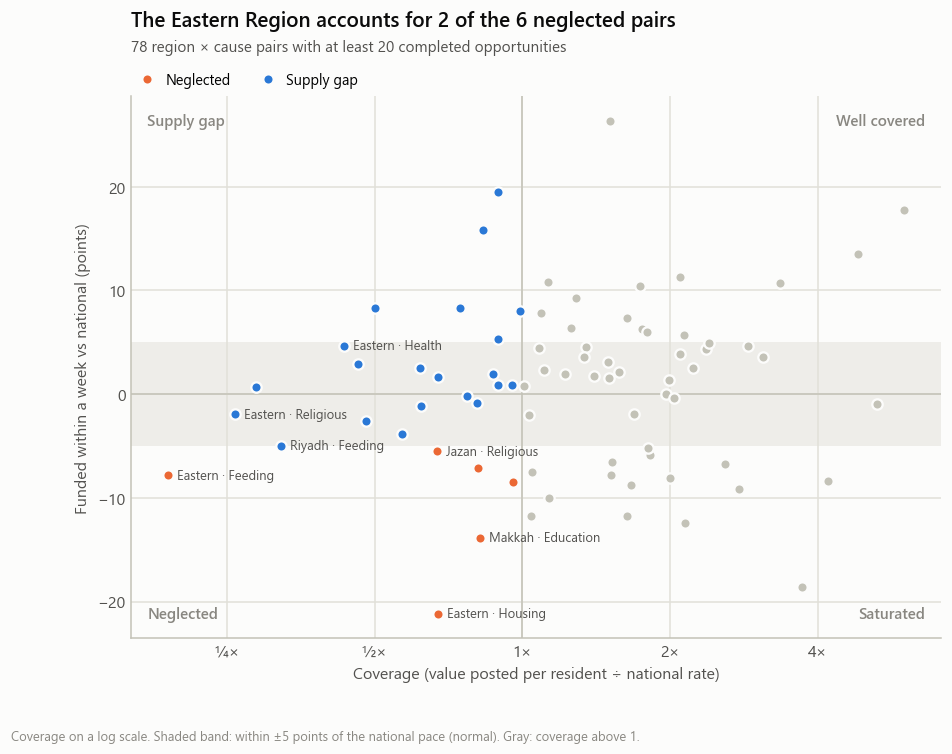

In [28]:
pts = gap.dropna(subset=["speed"])
colors = {"Neglected": viz.SERIES[1], "Supply gap": viz.SERIES[0]}
fig, ax = plt.subplots(figsize=(9.5, 6.4))
for name, grp in pts.groupby("situation"):
    ax.scatter(grp.coverage, grp.speed, s=46, color=colors.get(name, viz.CONTEXT),
               edgecolor=viz.SURFACE, linewidth=1.5, label=name if name in colors else None, zorder=3)
ax.set_xscale("log", base=2)
ax.axvline(1, color=viz.AXIS, linewidth=1, zorder=1)
ax.axhspan(-TOL, TOL, color=viz.GRID, alpha=0.5, zorder=0, linewidth=0)   # normal-pace band
ax.axhline(0, color=viz.AXIS, linewidth=1, zorder=1)
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["¼×", "½×", "1×", "2×", "4×"])
ax.set_xlabel("Coverage (value posted per resident ÷ national rate)")
ax.set_ylabel("Funded within a week vs national (points)")
for label, x, y, ha, va in [("Neglected", 0.02, 0.03, "left", "bottom"), ("Supply gap", 0.02, 0.97, "left", "top"),
                            ("Saturated", 0.98, 0.03, "right", "bottom"), ("Well covered", 0.98, 0.97, "right", "top")]:
    ax.text(x, y, label, transform=ax.transAxes, ha=ha, va=va, fontsize=10, color=viz.MUTED, fontweight="semibold")
placed = []   # label the lowest-coverage pairs, skipping any too close to one already labelled
for _, r in pd.concat([pts[pts.situation == "Neglected"].nsmallest(6, "coverage"),
                       pts[pts.situation == "Supply gap"].nsmallest(6, "coverage")]).iterrows():
    x, y = np.log2(r.coverage), r.speed
    if any(abs(x - px) < 0.55 and abs(y - py) < 3 for px, py in placed):
        continue
    placed.append((x, y))
    ax.annotate(f"{r.region_en} · {r.cause}", (r.coverage, r.speed), xytext=(6, 0), textcoords="offset points",
                fontsize=8.5, color=viz.INK_2, va="center")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1))
counts = pts.situation.value_counts()
neg = pts[pts.situation == "Neglected"]
top_region = neg.region_en.value_counts()
region_name = {"Eastern": "The Eastern Region"}.get(top_region.index[0], top_region.index[0])
viz.title(ax, f"{region_name} accounts for {top_region.iloc[0]} of the {len(neg)} neglected pairs",
          f"{len(pts)} region × cause pairs with at least {MIN_N} completed opportunities")
viz.note(fig, f"Coverage on a log scale. Shaded band: within ±{TOL} points of the national pace (normal). Gray: coverage above 1.")
viz.save(fig, "3_3_quadrants")
plt.show()

under = counts.get("Supply gap", 0) + counts.get("Neglected", 0)
viz.takeaway(f"Of the {under} under-covered pairs, <b>{counts.get('Supply gap', 0)}</b> are supply gaps (donors fund what is "
             f"posted at the normal pace or faster, so the bottleneck is posting) and <b>{counts.get('Neglected', 0)}</b> are "
             f"neglected (little posted and slow to fund). <b>{top_region.index[0]}</b> has {top_region.iloc[0]} of the "
             f"neglected pairs: it is both under-posted and under-funded.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">3.4</span>Where the next riyal should go

The pairs with the clearest gaps: coverage below **0.75** (at most three quarters of the fair share) and at least 20 completed opportunities, ranked by coverage. The two lists call for different actions.

In [29]:
def priority(kind):
    t = gap[(gap.situation == kind) & (gap.coverage < 0.75)].sort_values("coverage")
    t = t.assign(week_vs=lambda x: x.speed.map(lambda v: f"{v:+.0f} pts"))
    return t[["region_en", "cause", "coverage", "week", "week_vs", "n", "associations_per_100k"]].rename(columns={
        "region_en": "Region", "cause": "Cause", "coverage": "Coverage", "week": "Funded within a week",
        "week_vs": "vs national", "n": "Opportunities", "associations_per_100k": "Associations per 100k"})

neglected, supply = priority("Neglected"), priority("Supply gap")
fmt = dict(pct=["Funded within a week"], ints=["Opportunities"],
           decimals={"Coverage": 2, "Associations per 100k": 1})
display(viz.table(neglected, **fmt,
                  caption="Neglected: little posted and slow to fund → grants or matching funds"))
display(viz.table(supply, **fmt, caption="Supply gaps: donors respond, little posted → help associations post more"))
pd.concat([neglected.assign(Situation="Neglected"), supply.assign(Situation="Supply gap")]).to_csv(
    ROOT / "outputs/priority_pairs.csv", index=False, encoding="utf-8-sig")

viz.takeaway(f"<b>{len(neglected)}</b> pairs need money that donors are not providing quickly: grants or matching funds. "
             f"<b>{len(supply)}</b> pairs need more posted: donors already respond, so funding associations' capacity "
             "to prepare and publish opportunities there is the better use of a riyal.")

Region,Cause,Coverage,Funded within a week,vs national,Opportunities,Associations per 100k
Eastern,Feeding,0.19,75%,-8 pts,45,0.5
Jazan,Religious,0.67,75%,-6 pts,32,1.5
Eastern,Housing,0.67,37%,-21 pts,147,0.6


Region,Cause,Coverage,Funded within a week,vs national,Opportunities,Associations per 100k
Eastern,Religious,0.26,79%,-2 pts,29,0.4
Makkah,Mosques,0.29,59%,+1 pts,128,0.2
Riyadh,Feeding,0.32,78%,-5 pts,200,1.2
Eastern,Health,0.43,80%,+5 pts,77,0.5
Eastern,Mosques,0.46,62%,+3 pts,114,0.1
Eastern,Social,0.48,67%,-3 pts,171,0.9
Riyadh,Housing,0.50,66%,+8 pts,170,0.8
Riyadh,Social,0.57,66%,-4 pts,350,1.3
Makkah,Housing,0.62,60%,+3 pts,173,1.1
Riyadh,Religious,0.62,79%,-1 pts,99,0.7


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">3.5</span>Why little is posted: the association side

Coverage measures what is posted. When a region gets little, the cause can be on the association side, and it matters which part: a region may have **few associations on Ehsan**, associations that are there but **do not post projects**, associations that post **rarely**, or postings that are **small**. The value posted per resident splits exactly into these four parts:

> value per resident = partner associations per resident × share of them that post projects × opportunities per posting association × average opportunity size

Each part is shown relative to the national level (1.0 = national), so the four numbers multiply to the region's overall level. The number of partner associations per region comes from the map on Ehsan's statistics page (`data_raw/ehsan_dashboard/`).

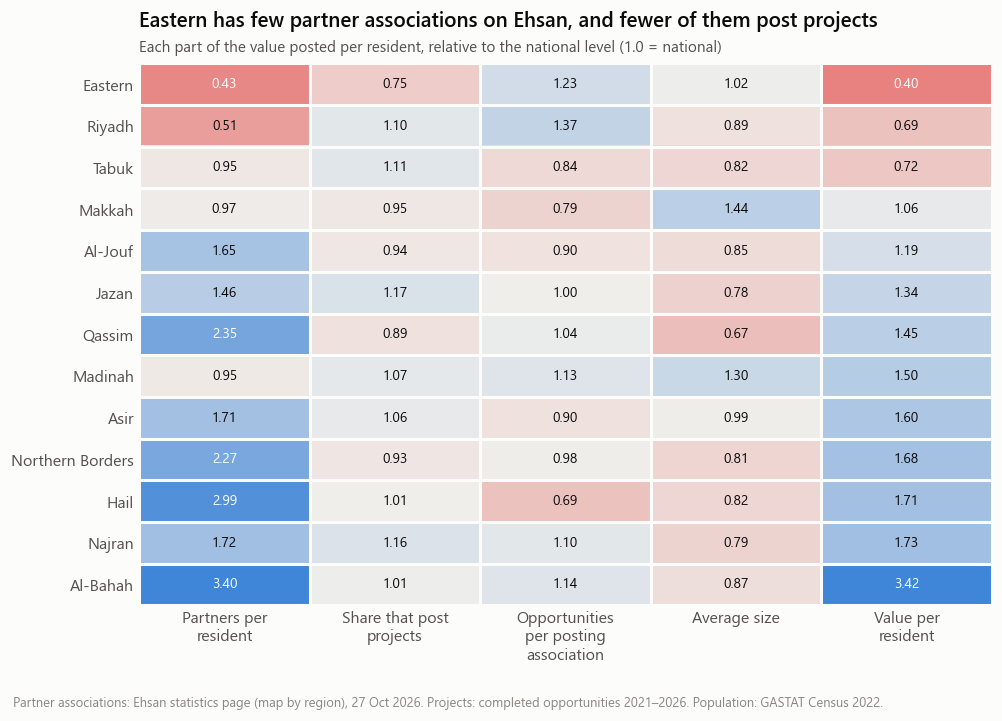

In [30]:
import textwrap

partners = pd.read_csv(ROOT / "data_raw/ehsan_dashboard/partner_associations_by_region.csv").set_index("region_en")

sides = (done.dropna(subset=["region_en"]).groupby("region_en")
         .agg(posting=("partner_name", "nunique"), n=("uid", "size"), value=("amount_sar", "sum"))
         .join(partners.partner_associations.rename("partners"))
         .join(population.set_index("region_en").total.rename("people")))
PARTS = {
    "Partners per resident": ("partners", "people"),
    "Share that post projects": ("posting", "partners"),
    "Opportunities per posting association": ("n", "posting"),
    "Average size": ("value", "n"),
}
parts = pd.DataFrame({name: (sides[a] / sides[b]) / (sides[a].sum() / sides[b].sum())
                      for name, (a, b) in PARTS.items()})
parts["Value per resident"] = parts.prod(axis=1)
assert np.allclose(parts["Value per resident"],
                   (sides.value / sides.people) / (sides.value.sum() / sides.people.sum()))
parts = parts.sort_values("Value per resident")

fig, ax = plt.subplots(figsize=(10, 6.4))
viz.heat(ax, parts, center=1.0, log=True, low_is_bad=True, fmt=lambda v: f"{v:.2f}", limits=2)
ax.set_xticks(range(parts.shape[1]), [textwrap.fill(col, 16) for col in parts.columns])
low = parts.index[0]
assert (parts.loc[low, ["Partners per resident", "Share that post projects"]] < 1).all()
viz.title(ax, f"{low} has few partner associations on Ehsan, and fewer of them post projects",
          "Each part of the value posted per resident, relative to the national level (1.0 = national)")
viz.note(fig, "Partner associations: Ehsan statistics page (map by region), 27 Oct 2026. Projects: completed "
              "opportunities 2021–2026. Population: GASTAT Census 2022.")
viz.save(fig, "3_5_association_side")
plt.show()

per_assoc = done.groupby("partner_name").size()
weakest = parts.drop(columns="Value per resident").idxmin(axis=1)
under = parts[parts["Value per resident"] < 1].index
reasons = "; ".join(f"<b>{r}</b>: {weakest[r].lower()} ({parts.loc[r, weakest[r]]:.2f})" for r in under)
viz.takeaway(f"Regions below the national level and their weakest part: {reasons}. The Eastern Region has "
             f"<b>{parts.loc[low, 'Partners per resident']:.2f}×</b> the national number of partner associations per "
             f"resident and <b>{parts.loc[low, 'Share that post projects']:.2f}×</b> the share that post projects, but those "
             f"that post are <b>more</b> active than average ({parts.loc[low, 'Opportunities per posting association']:.2f}×). "
             f"Nationally, <b>{(per_assoc == 1).mean():.0%}</b> of associations that posted a project completed only one.")

**How to read this.** A low **partners per resident** calls for bringing more associations onto Ehsan. A low **share that post projects** calls for helping associations already on Ehsan to prepare their first project. A low **opportunities per posting association** calls for helping active associations post again. Two cautions: the map most likely places each association at its headquarters, while projects are placed where they happen; and some partners work only in sections outside this analysis (for example orphan sponsorship), which lowers the share that post projects everywhere, not only in one region.

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">3.6</span>How robust is this?

Two checks on the choices behind the measures.

In [31]:
rank_corr = gap.coverage.corr(gap.coverage_saudi, method="spearman")
same_side = ((gap.coverage < 1) == (gap.coverage_saudi < 1)).mean()
checks = pd.DataFrame([
    ("Coverage per Saudi resident instead of all residents: rank correlation", f"{rank_corr:.2f}"),
    ("Pairs on the same side of 1.0 under both populations", f"{same_side:.0%}"),
], columns=["Check", "Result"])
display(viz.table(checks))
viz.takeaway(f"Using the Saudi population instead of all residents (the platform mainly serves citizens) barely "
             f"changes coverage: rank correlation <b>{rank_corr:.2f}</b>, and <b>{same_side:.0%}</b> of pairs stay on the same "
             "side of the fair share. The Eastern Region's gap is not explained by its large non-Saudi workforce.")

Check,Result
Coverage per Saudi resident instead of all residents: rank correlation,0.98
Pairs on the same side of 1.0 under both populations,87%


**Limits of this section.** Population is a rough stand-in for need: a region with lower poverty may need less, and a better yardstick (for example social-security beneficiaries per region) was not available in a matching form. Coverage also counts only what is posted **on Ehsan**: a region whose associations raise money elsewhere will look under-covered here. Both are reasons to read the lists in 3.4 as **where to look first**, not as a final ranking of need.

## <span style="display:inline-block;min-width:1.8em;padding:.1em .4em;margin-right:.5em;border-radius:.4em;background:#3987e5;color:#fff;text-align:center;font-weight:600">4</span>Timing
<div style="border-bottom:1px solid rgba(127,127,127,.35);margin:-4px 0 14px"></div>

Does **when** an opportunity is posted change how fast donors fund it? Ehsan records dates but not times, so the questions here are about the calendar: the Hijri month, salary day and the day of the week.

Speed is measured as in section 3: the share of opportunities **funded within a week**, leaving out Ehsan's launch period (1.5). Some years were faster than others overall, so each month is compared with **the average of its own Hijri year**: Sha'ban 1445 against all of 1445, and so on. A month that is slow in every year is slow because of the month, not because of one bad year. As before, a difference of under **5 points** counts as the normal pace.

In [32]:
from hijridate import Gregorian

HIJRI_MONTHS = ["Muharram", "Safar", "Rabi' I", "Rabi' II", "Jumada I", "Jumada II",
                "Rajab", "Sha'ban", "Ramadan", "Shawwal", "Dhu al-Qa'dah", "Dhu al-Hijjah"]
SHABAN = "Sha'ban"
MONTH_TICKS = [m.replace("Dhu al-", "Dhu al-\n") for m in HIJRI_MONTHS]   # two lines so labels fit

def hijri(dates):
    """Hijri (year, month) for each date; converted once per distinct day."""
    days = dates.dt.normalize()
    lookup = {d: Gregorian(d.year, d.month, d.day).to_hijri() for d in days.dropna().unique()}
    h = days.map(lookup)
    return h.map(lambda x: getattr(x, "year", np.nan)), h.map(lambda x: getattr(x, "month", np.nan))

timed = done.dropna(subset=["days_to_fund"]).copy()
timed["hijri_year"], timed["hijri_month"] = hijri(timed.publish_date)
timed["ramadan"] = timed.hijri_month == 9
timed["weekday"] = timed.publish_date.dt.day_name()
timed["week"] = timed.days_to_fund <= 7
timed["vs_year"] = (timed.week - timed.groupby("hijri_year").week.transform("mean")) * 100   # points vs its own year

# postings count every completed opportunity, launch period included (what was posted)
posted_year, posted_month = hijri(done.publish_date)
postings = done.groupby(posted_month).size() / posted_year.groupby(posted_month).nunique()

months = (timed.groupby("hijri_month")
          .agg(n=("uid", "size"), week=("week", "mean"),
               vs_year=("vs_year", "mean"), days=("days_to_fund", "median")))
months["per_month"] = postings
months.index = HIJRI_MONTHS
print(f"{len(timed):,} completed opportunities used for speed, "
      f"{timed.hijri_year.min()}–{timed.hijri_year.max()} AH")

8,909 completed opportunities used for speed, 1442–1448 AH


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">4.1</span>When opportunities are posted

Each Hijri month appears five or six times between 2021 and 2026, so postings are shown as the average per occurrence of the month.

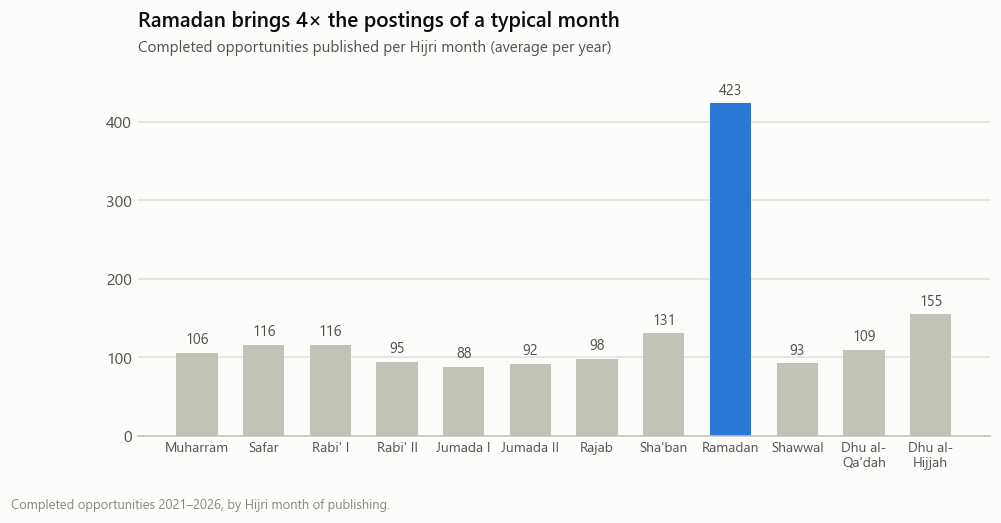

In [33]:
typical = months.per_month.drop("Ramadan").median()
fig, ax = plt.subplots(figsize=(10, 4.4))
viz.vbar(ax, months.index, months.per_month, highlight=["Ramadan"], fmt=lambda v: f"{v:.0f}")
ax.set_xticks(range(12), MONTH_TICKS, fontsize=9)
viz.title(ax, f"Ramadan brings {months.per_month['Ramadan'] / typical:.0f}× the postings of a typical month",
          "Completed opportunities published per Hijri month (average per year)")
viz.note(fig, "Completed opportunities 2021–2026, by Hijri month of publishing.")
viz.save(fig, "4_1_postings_by_month")
plt.show()

viz.takeaway(f"About <b>{months.per_month['Ramadan']:.0f}</b> opportunities are posted in a typical Ramadan, against "
             f"<b>{typical:.0f}</b> in a typical other month: Ramadan alone holds <b>{(posted_month == 9).mean():.0%}</b> "
             f"of all postings. Postings also rise in {SHABAN} ({months.per_month[SHABAN]:.0f}) and Dhu al-Hijjah "
             f"({months.per_month['Dhu al-Hijjah']:.0f}), around Hajj and Eid al-Adha.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">4.2</span>How fast each month funds

Each bar shows how far a month's within-a-week share is from **its own year's** average, averaged over the years. Months beyond the shaded ±5-point band are coloured. The table below checks the slowest month, the fastest month and Ramadan year by year.

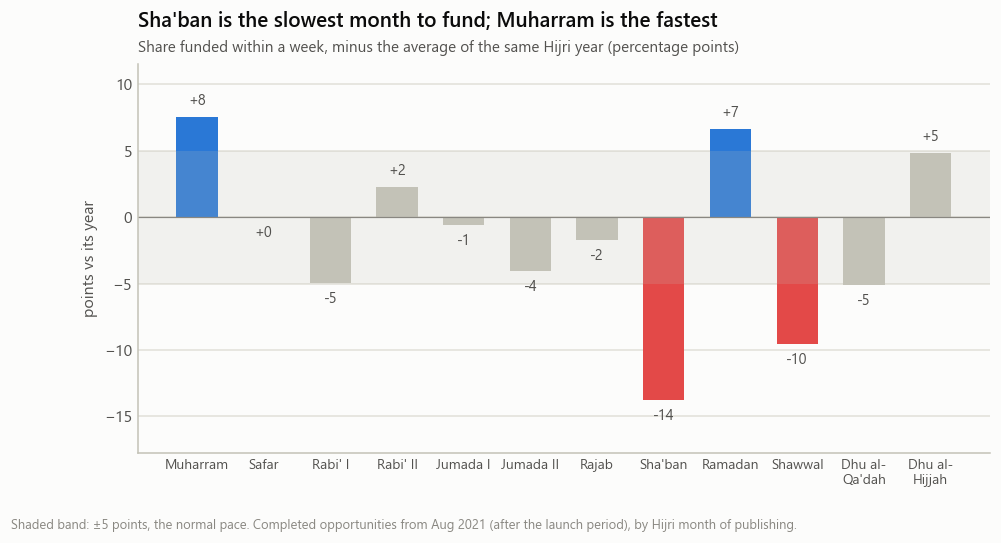

Hijri year,Year average,Sha'ban (pts),Ramadan (pts),Muharram (pts)
1442,62%,–,–,–
1443,77%,-11,-7,15
1444,66%,-11,-4,15
1445,59%,-28,15,12
1446,76%,-9,10,-4
1447,76%,-10,15,2
1448,61%,–,–,6


In [34]:
fig, ax = plt.subplots(figsize=(10, 4.6))
colors = [viz.DIVERGING[2] if round(v) < -TOL else viz.DIVERGING[0] if round(v) > TOL else viz.CONTEXT
          for v in months.vs_year]   # by the rounded label, so colour and label agree
ax.bar(range(12), months.vs_year, width=0.62, color=colors)
ax.axhspan(-TOL, TOL, color=viz.CONTEXT, alpha=0.18, lw=0)
ax.axhline(0, color=viz.MUTED, lw=0.8)
for i, v in enumerate(months.vs_year):
    ax.text(i, v + (0.6 if v >= 0 else -0.6), f"{round(v):+d}", ha="center", va="bottom" if v >= 0 else "top",
            fontsize=9.5, color=viz.INK_2)
ax.set_xticks(range(12), MONTH_TICKS, fontsize=9)
ax.set_ylim(months.vs_year.min() - 4, months.vs_year.max() + 4)
ax.grid(axis="x", visible=False)
ax.set_ylabel("points vs its year")
slow, fast = months.vs_year.idxmin(), months.vs_year.idxmax()
next_slow = months.vs_year.drop(slow).idxmin()
viz.title(ax, f"{slow} is the slowest month to fund; {fast} is the fastest",
          "Share funded within a week, minus the average of the same Hijri year (percentage points)")
viz.note(fig, "Shaded band: ±5 points, the normal pace. Completed opportunities from Aug 2021 (after the launch period), "
              "by Hijri month of publishing.")
viz.save(fig, "4_2_speed_by_month")
plt.show()

def month_no(name):
    return HIJRI_MONTHS.index(name) + 1

shown = list(dict.fromkeys([slow, "Ramadan", fast]))
by_year = (timed.pivot_table(index="hijri_year", columns="hijri_month", values="vs_year", aggfunc="mean")
           [[month_no(m) for m in shown]])
by_year.columns = [f"{m} (pts)" for m in shown]
by_year.insert(0, "Year average", timed.groupby("hijri_year").week.mean())
counts = timed.pivot_table(index="hijri_year", columns="hijri_month", values="uid", aggfunc="size")
for m in shown:   # a month needs MIN_N opportunities in a year to be judged
    by_year.loc[counts[month_no(m)].reindex(by_year.index).fillna(0) < MIN_N, f"{m} (pts)"] = np.nan
by_year = by_year.reset_index().rename(columns={"hijri_year": "Hijri year"})
display(viz.table(by_year, pct=["Year average"], decimals={f"{m} (pts)": 0 for m in shown},
                  caption="Each month against its own year, year by year (– = fewer than 20 opportunities)"))

slow_col, ram_col = by_year[f"{slow} (pts)"].dropna(), by_year["Ramadan (pts)"].dropna()
slow_month = timed[timed.hijri_month == month_no(slow)]
waits = (hijri(slow_month.completed_date)[1] == month_no(slow) + 1).mean()
viz.takeaway(f"<b>{slow}</b> is below its year's average in <b>{(slow_col < 0).sum()} of {len(slow_col)}</b> years "
             f"(on average {-months.vs_year[slow]:.0f} points), and <b>{waits:.0%}</b> of its opportunities are completed "
             f"in {HIJRI_MONTHS[month_no(slow) % 12]}: donors appear to hold their giving for the next month. "
             f"<b>Ramadan</b> is above its year's average in {(ram_col > 0).sum()} of {len(ram_col)} years "
             f"(on average {months.vs_year['Ramadan']:+.0f} points) despite {months.per_month['Ramadan'] / typical:.0f}× the "
             f"postings. <b>{next_slow}</b> is the next slowest ({months.vs_year[next_slow]:+.0f} points) and <b>{fast}</b> "
             f"the fastest ({months.vs_year[fast]:+.0f} points).")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">4.3</span>Salary day

Most salaries in Saudi Arabia, including all government salaries, are paid on the **27th** of each Gregorian month. If pay day drives giving, more opportunities should be **completed** (reach their target) on and after the 27th. Each calendar day is compared with the average day, allowing for days 29–31 not occurring in every month.

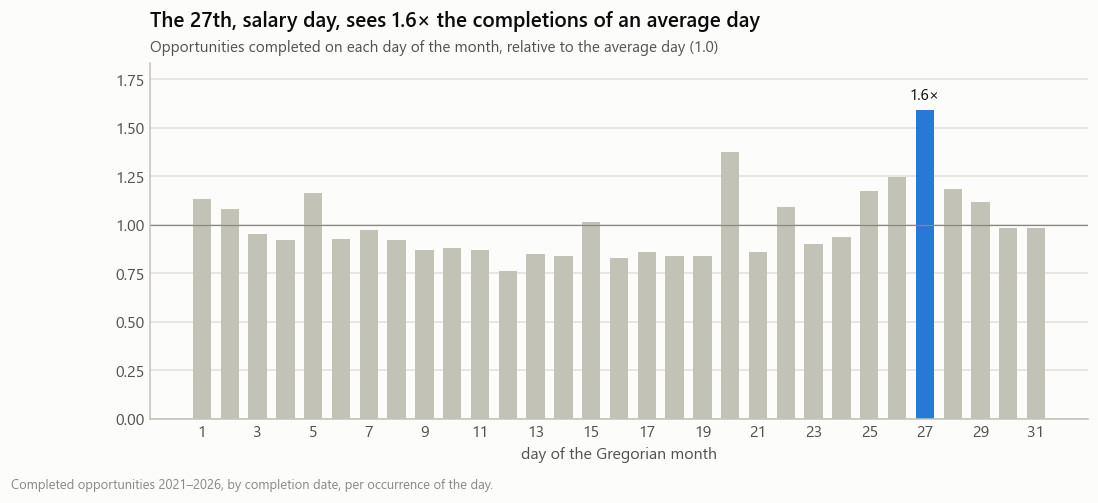

In [35]:
span = pd.Series(pd.date_range(timed.completed_date.min(), timed.completed_date.max()))
occurrences = span.dt.day.value_counts().sort_index()

def relative_by_day(dates):
    """Completions per occurrence of each calendar day, relative to the average day."""
    per_day = dates.dt.day.value_counts().sort_index() / occurrences
    return per_day / per_day.mean()

by_day = relative_by_day(timed.completed_date)
by_day_nr = relative_by_day(timed.completed_date[hijri(timed.completed_date)[1] != 9])

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(by_day.index, by_day, width=0.66, color=[viz.BLUE if d == 27 else viz.CONTEXT for d in by_day.index])
ax.axhline(1, color=viz.MUTED, lw=0.8)
ax.text(27, by_day[27] + 0.03, f"{by_day[27]:.1f}×", ha="center", va="bottom", fontsize=10, color=viz.INK)
ax.set_xticks(range(1, 32, 2))
ax.set_ylim(0, by_day.max() * 1.15)
ax.grid(axis="x", visible=False)
ax.set_xlabel("day of the Gregorian month")
viz.title(ax, f"The 27th, salary day, sees {by_day[27]:.1f}× the completions of an average day",
          "Opportunities completed on each day of the month, relative to the average day (1.0)")
viz.note(fig, "Completed opportunities 2021–2026, by completion date, per occurrence of the day.")
viz.save(fig, "4_3_salary_day")
plt.show()

payday = by_day[[27, 28, 29]].mean()
mid = by_day[10:20].mean()
viz.takeaway(f"Completions peak on the <b>27th</b> ({by_day[27]:.1f}× the average day) and stay high to the end of the month "
             f"(27th–29th: {payday:.1f}×), against {mid:.1f}× mid-month (10th–20th). Leaving Ramadan out changes little "
             f"(27th: {by_day_nr[27]:.1f}×), so this is not a Ramadan effect: <b>donors give when they are paid</b>.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">4.4</span>Day of the week

Two views: the day opportunities are **completed** (when do donors give?), and the day an opportunity is **posted** (does it change speed?).

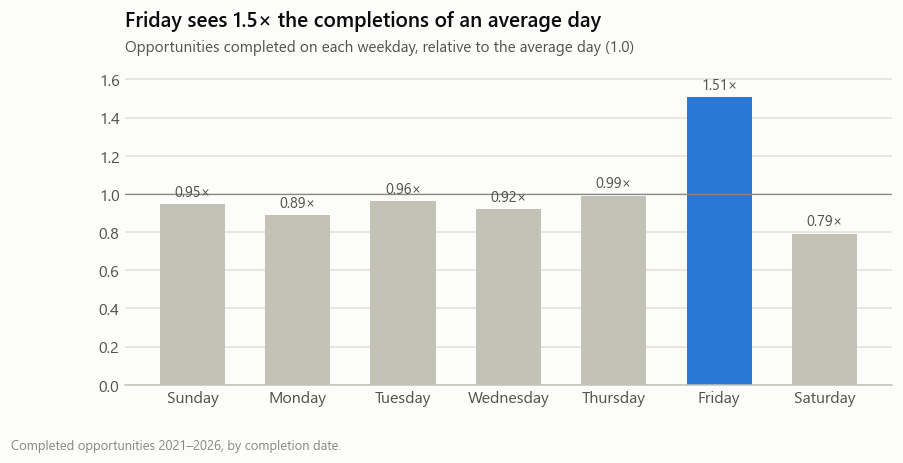

Posted on,Opportunities,Funded within a week,vs its year (pts)
Sunday,"1,661",66%,-4.0
Monday,"1,199",69%,-0.6
Tuesday,"1,205",69%,-0.6
Wednesday,"1,413",66%,-3.1
Thursday,"1,348",71%,0.4
Friday,"1,165",76%,5.9
Saturday,918,75%,5.5


In [36]:
ORDER = ["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
completed_on = timed.completed_date.dt.day_name().value_counts() / span.dt.day_name().value_counts()
completed_on = (completed_on / completed_on.mean()).reindex(ORDER)
posted = (timed.groupby("weekday").agg(n=("uid", "size"), week=("week", "mean"), vs_year=("vs_year", "mean"))
          .reindex(ORDER))

fig, ax = plt.subplots(figsize=(9, 3.8))
viz.vbar(ax, ORDER, completed_on, highlight=[completed_on.idxmax()], fmt=lambda v: f"{v:.2f}×")
ax.axhline(1, color=viz.MUTED, lw=0.8)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.1f}")
viz.title(ax, f"{completed_on.idxmax()} sees {completed_on.max():.1f}× the completions of an average day",
          "Opportunities completed on each weekday, relative to the average day (1.0)")
viz.note(fig, "Completed opportunities 2021–2026, by completion date.")
viz.save(fig, "4_4_weekday")
plt.show()

display(viz.table(posted.reset_index().rename(columns={"weekday": "Posted on", "n": "Opportunities",
                                                       "week": "Funded within a week", "vs_year": "vs its year (pts)"}),
                  ints=["Opportunities"], pct=["Funded within a week"], decimals={"vs its year (pts)": 1},
                  caption="Speed by the day the opportunity was posted"))
beyond = posted.index[posted.vs_year.abs() > TOL].tolist()
others = len(ORDER) - len(beyond)
viz.takeaway(f"Donors complete <b>{completed_on.max():.1f}×</b> as many opportunities on {completed_on.idxmax()} as on an "
             f"average day. The day an opportunity is <b>posted</b> matters less: "
             + (f"opportunities posted on {' and '.join(beyond)} differ from their year's pace by "
                f"{', '.join(f'{posted.vs_year[d]:+.0f}' for d in beyond)} points, and the other {others} days are within 5." if beyond
                else "every weekday is within 5 points of its year's pace."))

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">4.5</span>What timing means

The timing features computed here (Hijri month, Ramadan, weekday) are kept for the model in section 5.

In [37]:
viz.takeaway(f"<b>{slow} is a poor time to rely on donors for urgent needs</b>: opportunities posted then "
             f"are the slowest of the year, every year, and many wait for {HIJRI_MONTHS[month_no(slow) % 12]}. <b>Ramadan is a "
             f"good time to post</b>: it absorbs {months.per_month['Ramadan'] / typical:.0f}× the usual postings and on "
             f"average still funds faster than its year's pace. <b>Appeals land best around the 27th and on {completed_on.idxmax()}s</b>, "
             "when donors give most. These are patterns, not proof of cause: other things also change with the calendar.")

## <span style="display:inline-block;min-width:1.8em;padding:.1em .4em;margin-right:.5em;border-radius:.4em;background:#3987e5;color:#fff;text-align:center;font-weight:600">5</span>Predicting slow funding
<div style="border-bottom:1px solid rgba(127,127,127,.35);margin:-4px 0 14px"></div>

Which features of an opportunity, known on the day it is posted, predict that donors will take **more than a week** to fund it? A model that predicts slow funding shows **what donors respond to**, and how much of their behaviour can be seen in advance at all. It is a tool for understanding donors, not a system for any platform to run.

The model gives each opportunity a **risk score** between 0% and 100%: how likely it is to take more than a week. It may only use what is known **at posting**:

| Feature | Why it might matter |
|---|---|
| Cause, target group, Ehsan section | Some causes are harder to fund (section 2) |
| Region | Donors might favour some regions (section 3 says they do not) |
| Amount, number of beneficiaries | Larger amounts take longer to fill |
| **Amount per beneficiary** | SAR 500,000 for 2 people reads differently from the same for 200 |
| Hijri month, weekday of posting | Sha'ban is slow, Ramadan is fast (section 4) |
| **Days until salary day (the 27th)** | Donors give most when paid (4.3) |
| Association's earlier postings | Experienced associations may write better appeals |
| **Association's track record** | Share of its earlier opportunities that took more than a week, counting only those already **completed** on the posting day |
| **Competition** | Opportunities open on Ehsan on the posting day, and new ones posted in the 7 days before |

The four features in bold were added after the first version of the model (the gain is shown in 5.2). Page visits and donation counts are left out, because they build up after posting and would leak the answer. The launch period is left out, as in sections 2–4.

In [38]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # silences a joblib core-count warning on Windows
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TEST_FROM = pd.Timestamp("2025-08-01")   # the latest 15 months are kept aside as the final test
model_data = timed.sort_values("publish_date").reset_index(drop=True)
model_data["hijri_month"] = model_data.hijri_month.astype(int).astype(str)
model_data["region_en"] = model_data.region_en.fillna("Unknown")
model_data["amount"] = np.log10(model_data.amount_sar)
model_data["beneficiaries_log"] = np.log10(model_data.beneficiaries)
model_data["association_history"] = np.log1p(model_data.groupby("partner_name").cumcount())   # earlier postings only
y = model_data.days_to_fund > 7

# amount per beneficiary (log scale, so amount minus beneficiaries)
model_data["per_beneficiary"] = model_data.amount - model_data.beneficiaries_log

# days from posting to the next 27th
day, month_days = model_data.publish_date.dt.day, model_data.publish_date.dt.days_in_month
model_data["to_payday"] = np.where(day <= 27, 27 - day, month_days - day + 27)

# track record: slow share of the association's opportunities completed BEFORE this one was posted,
# pulled toward the national rate when there are few of them (5 imaginary average opportunities)
national = y[model_data.publish_date < TEST_FROM].mean()
record, record_n = np.full(len(model_data), np.nan), np.zeros(len(model_data))
for _, g in model_data.groupby("partner_name"):
    completed, slow = g.completed_date.to_numpy(), y[g.index].to_numpy()
    for i, posted in zip(g.index, g.publish_date.to_numpy()):
        known = completed < posted
        record_n[i] = known.sum()
        record[i] = (slow[known].sum() + 5 * national) / (known.sum() + 5)
model_data["track_record"] = record
model_data["track_record_n"] = np.log1p(record_n)

# competition: opportunities open on the posting day, and new ones posted in the 7 days before
# (all completed opportunities, launch period included, since they competed for the same donors)
published, completed = np.sort(done.publish_date.dropna().to_numpy()), np.sort(done.completed_date.dropna().to_numpy())
t = model_data.publish_date.to_numpy()
open_now = np.searchsorted(published, t, "right") - np.searchsorted(completed, t, "right")
model_data["open_now"] = np.log1p(np.clip(open_now, 0, None))
model_data["posted_week"] = np.log1p(np.searchsorted(published, t, "left")
                                     - np.searchsorted(published, t - np.timedelta64(7, "D"), "left"))

CATEGORICAL = ["cause", "target_group", "region_en", "section", "hijri_month", "weekday"]
EARLIER = ["amount", "beneficiaries_log", "association_history"]
NEW = ["per_beneficiary", "to_payday", "track_record", "track_record_n", "open_now", "posted_week"]
NUMERIC = EARLIER + NEW
X = model_data[CATEGORICAL + NUMERIC]
test = model_data.publish_date >= TEST_FROM
span = lambda dates: f"{dates.min():%b %Y} – {dates.max():%b %Y}"
viz.tiles([("Opportunities for the model", f"{len(X):,}", span(model_data.publish_date)),
           ("Took more than a week", f"{y.mean():.0%}", "the share the model tries to spot"),
           ("Training", f"{(~test).sum():,}", span(model_data.publish_date[~test])),
           ("Final test, never seen in training", f"{test.sum():,}", span(model_data.publish_date[test]))])

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">5.1</span>A signal that had to be removed

Some opportunities have no beneficiary count. In the first version of the model this was the strongest predictor of all, which called for a check.

In [39]:
no_count = model_data.beneficiaries.isna()
check = (model_data.assign(year=model_data.publish_date.dt.year, no_count=no_count)
         .groupby(["year", "no_count"]).agg(n=("uid", "size"), slow=("days_to_fund", lambda s: (s > 7).mean()))
         .unstack("no_count"))
check.columns = [f"{'No count' if missing else 'Count shown'}: {'opportunities' if m == 'n' else 'slow'}"
                 for m, missing in check.columns]
check = check.reset_index().rename(columns={"year": "Published"})
display(viz.table(check, ints=[c for c in check.columns if "opportunities" in c],
                  pct=[c for c in check.columns if "slow" in c],
                  caption="Share taking more than a week, by whether the report shows a beneficiary count"))
missing_sections = model_data.loc[no_count, "section"].value_counts(normalize=True)
viz.takeaway(f"Opportunities without a count were mostly slow in 2022–2024 but mostly fast in 2025–2026, and "
             f"<b>{missing_sections.get('housing', 0) + missing_sections.get('mosques', 0):.0%}</b> of them are housing or mosque "
             "cases, whose report pages changed layout. The gap says how Ehsan's report page looked, not how donors behaved, "
             "so a model would learn the page design. Missing counts are therefore filled with the typical (median) value, "
             "and the model is not told which ones were missing.")

Published,Count shown: opportunities,No count: opportunities,Count shown: slow,No count: slow
2021,618,–,16%,–
2022,"1,537",68,23%,96%
2023,"2,035",29,41%,86%
2024,"1,638",43,34%,65%
2025,"1,178",342,28%,18%
2026,990,431,29%,17%


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">5.2</span>How well can it predict?

The model is checked fairly: trained only on the past and tested on a later period it never saw. This is done three times, a year apart:

- **Two validation years** (Aug 2023 – Jul 2024 and Aug 2024 – Jul 2025), each predicted by a model trained on everything published before it. The model is **chosen** by its average over these two years.
- **The final test**, the latest 15 months (Aug 2025 – Oct 2026), predicted by a model trained on everything before August 2025. It is looked at only once the model has been chosen.

Four models are compared:
- **Cause only**: the slow rate of each cause, which is what section 2 alone would suggest.
- **Logistic regression**: a simple, transparent model using all features.
- **Gradient-boosted trees** (many small decision trees, each correcting the previous ones), first with the **earlier features** only and then with **all features**, to show what the four new ones add.

The score is the **AUC**: if one slow and one fast opportunity are picked at random, how often the model gives the slow one the higher risk. 0.5 is a coin toss and 1.0 is perfect. A second, plainer measure: of the **20%** of opportunities the model rates riskiest, how many really were slow.

In [40]:
def encoder(numeric, dense=False):
    return ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=not dense), CATEGORICAL),
        ("numbers", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric)])

def trees(numeric, **settings):
    settings = {"max_depth": 3, "learning_rate": 0.05, "max_iter": 300, "random_state": 0, **settings}
    return make_pipeline(encoder(numeric, dense=True), HistGradientBoostingClassifier(**settings))

MODELS = {
    "Cause only": lambda: make_pipeline(
        ColumnTransformer([("cause", OneHotEncoder(handle_unknown="ignore"), ["cause"])]), LogisticRegression()),
    "Logistic regression": lambda: make_pipeline(encoder(NUMERIC), LogisticRegression(max_iter=3000)),
    "Gradient-boosted trees, earlier features": lambda: trees(EARLIER),
    "Gradient-boosted trees": lambda: trees(NUMERIC),
}
PERIODS = {"Aug 2023 – Jul 2024": ("2023-08-01", "2024-08-01"),
           "Aug 2024 – Jul 2025": ("2024-08-01", "2025-08-01"),
           "Latest 15 months (test)": (TEST_FROM, "2027-01-01")}
VALIDATION = list(PERIODS)[:2]
FLAG = 0.20
fitted, risk = {}, {}

def evaluate(name, make):
    """AUC one period ahead: train on everything published before the period, score the period.
    The model from the last period (trained on everything before the test) is the one kept."""
    row = {"Model": name}
    for label, (start, end) in PERIODS.items():
        train = model_data.publish_date < start
        period = (model_data.publish_date >= start) & (model_data.publish_date < end)
        model = make().fit(X[train], y[train])
        row[label] = roc_auc_score(y[period], model.predict_proba(X[period])[:, 1])
    fitted[name], risk[name] = model, model.predict_proba(X[test])[:, 1]
    flagged = risk[name] >= np.quantile(risk[name], 1 - FLAG)
    row["Validation average"] = np.mean([row[v] for v in VALIDATION])
    row["Slow among the riskiest 20%"] = y[test][flagged].mean()
    row["Slow opportunities found"] = y[test][flagged].sum() / y[test].sum()
    return row

COLUMNS = ["Model", *VALIDATION, "Validation average", "Latest 15 months (test)",
           "Slow among the riskiest 20%", "Slow opportunities found"]
def show(rows, caption):
    display(viz.table(rows[COLUMNS], pct=["Slow among the riskiest 20%", "Slow opportunities found"],
                      decimals={c: 2 for c in COLUMNS[1:5]}, caption=caption))

metrics = pd.DataFrame([evaluate(name, make) for name, make in MODELS.items()])
show(metrics, f"AUC one period ahead; riskiest 20% among the {test.sum():,} test opportunities, of which {y[test].mean():.0%} were slow")

best = metrics.loc[metrics["Validation average"].idxmax()]
best_name = best.Model
by_name = metrics.set_index("Model")
gain = by_name.loc["Gradient-boosted trees", list(PERIODS)] - by_name.loc["Gradient-boosted trees, earlier features", list(PERIODS)]
viz.takeaway(f"Chosen on the validation years: <b>{best_name.lower()}</b> (average AUC {best['Validation average']:.2f}). "
             f"On the final test it scores <b>{best['Latest 15 months (test)']:.2f}</b>; of the 20% it rates riskiest, "
             f"<b>{best['Slow among the riskiest 20%']:.0%}</b> turned out slow, against {y[test].mean():.0%} overall, and "
             f"they hold <b>{best['Slow opportunities found']:.0%}</b> of all slow opportunities. The four new features "
             f"raise the AUC in <b>{(gain > 0).sum()} of {len(gain)}</b> periods (by {gain.min():+.2f} to {gain.max():+.2f}). "
             f"Cause alone is no better than a coin toss on the newest data "
             f"(AUC {by_name.loc['Cause only', 'Latest 15 months (test)']:.2f}). The prediction is <b>useful but modest</b>: "
             "much of what makes an opportunity slow is not visible on the day it is posted.")

Model,Aug 2023 – Jul 2024,Aug 2024 – Jul 2025,Validation average,Latest 15 months (test),Slow among the riskiest 20%,Slow opportunities found
Cause only,0.65,0.63,0.64,0.52,25%,24%
Logistic regression,0.74,0.72,0.73,0.67,41%,29%
"Gradient-boosted trees, earlier features",0.69,0.72,0.70,0.65,43%,31%
Gradient-boosted trees,0.73,0.74,0.74,0.70,41%,29%


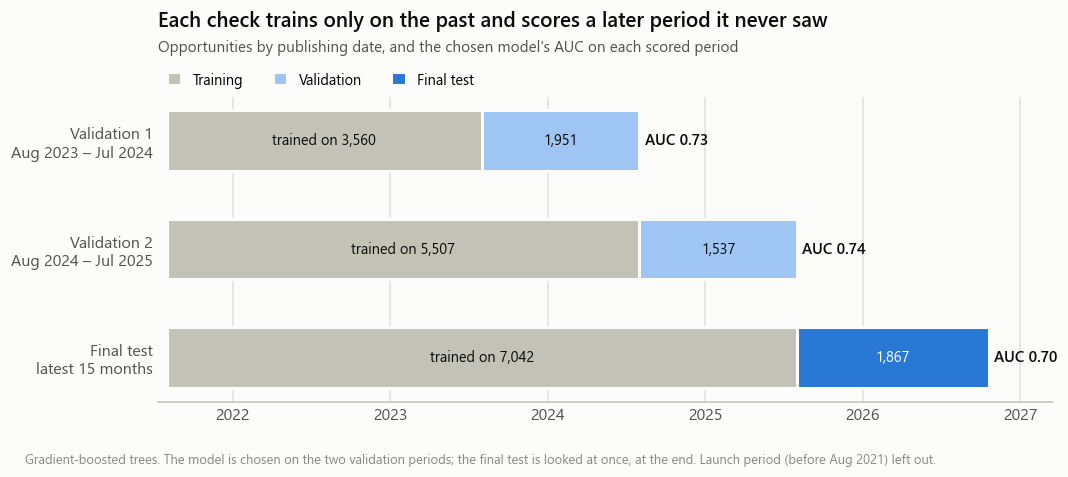

In [41]:
import matplotlib.dates as mdates

first, last = model_data.publish_date.min(), model_data.publish_date.max()
role_color = {"Training": viz.CONTEXT, "Validation": viz.SEQ[1], "Final test": viz.BLUE}
fig, ax = plt.subplots(figsize=(10.5, 3.6))
for row, (label, (start, end)) in enumerate(PERIODS.items()):
    start, end = pd.Timestamp(start), min(pd.Timestamp(end), last)
    trained = (model_data.publish_date < start).sum()
    scored = ((model_data.publish_date >= start) & (model_data.publish_date <= end)).sum()
    role = "Final test" if label == list(PERIODS)[-1] else "Validation"
    x0, x1, x2 = mdates.date2num([first, start, end])
    named = set(ax.get_legend_handles_labels()[1])   # name each colour once, for the legend
    ax.barh(row, x1 - x0, left=x0, height=0.56, color=role_color["Training"], edgecolor=viz.SURFACE, linewidth=2,
            label=None if "Training" in named else "Training")
    ax.barh(row, x2 - x1, left=x1, height=0.56, color=role_color[role], edgecolor=viz.SURFACE, linewidth=2,
            label=None if role in named else role)
    ax.text((x0 + x1) / 2, row, f"trained on {trained:,}", ha="center", va="center", fontsize=9.5, color=viz.INK)
    ax.text((x1 + x2) / 2, row, f"{scored:,}", ha="center", va="center", fontsize=9.5,
            color="#ffffff" if role == "Final test" else viz.INK)
    ax.text(x2 + 12, row, f"AUC {by_name.loc[best_name, label]:.2f}", va="center", fontsize=10, color=viz.INK,
            fontweight="semibold")
ax.set_yticks(range(len(PERIODS)), [f"Validation 1\n{list(PERIODS)[0]}", f"Validation 2\n{list(PERIODS)[1]}",
                                    "Final test\nlatest 15 months"])
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlim(mdates.date2num(first) - 20, mdates.date2num(last) + 150)
viz.only_grid(ax, "x")
ax.legend()
viz.title(ax, "Each check trains only on the past and scores a later period it never saw",
          f"Opportunities by publishing date, and the chosen model's AUC on each scored period")
viz.note(fig, f"{best_name}. The model is chosen on the two validation periods; the final test is looked at once, at the end. "
              "Launch period (before Aug 2021) left out.")
viz.save(fig, "5_0_train_test")
plt.show()

**Why split by time, not at random?** The question is whether what donors did in the past still holds later, so the test always predicts a later period from earlier ones. A random split would also put near-copies in both training and test: an association often posts several similar opportunities in the same week, and if some land in training, the model has already seen the answer for the rest. It would also mix the years and hide changes on Ehsan over time. The table shows how much a random split would overstate the model.

In [42]:
from sklearn.model_selection import train_test_split

random_auc = []
for seed in range(5):   # five different random draws of the same size as the final test
    train_idx, test_idx = train_test_split(X.index, test_size=test.mean(), random_state=seed)
    model = MODELS[best_name]().fit(X.loc[train_idx], y[train_idx])
    random_auc.append(roc_auc_score(y[test_idx], model.predict_proba(X.loc[test_idx])[:, 1]))
split_check = pd.DataFrame({
    "How the test opportunities are picked": [f"At random, {test.mean():.0%} of all years (average of 5 draws)",
                                              "By time: the latest 15 months (used in this notebook)"],
    "AUC": [np.mean(random_auc), best["Latest 15 months (test)"]]})
display(viz.table(split_check, decimals={"AUC": 2}, caption=f"{best_name}, same features, same test size"))
viz.takeaway(f"A random split would report an AUC of <b>{np.mean(random_auc):.2f}</b> (between {min(random_auc):.2f} and "
             f"{max(random_auc):.2f} over five draws), against <b>{best['Latest 15 months (test)']:.2f}</b> when the model "
             "has to predict a later period. The gap is how much a random split would <b>overstate</b> the model; the "
             "lower, time-based figure is the one reported.")

How the test opportunities are picked,AUC
"At random, 21% of all years (average of 5 draws)",0.82
By time: the latest 15 months (used in this notebook),0.70


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">5.3</span>Does a bigger model help?

A fair question is whether the score is modest only because the model is small. Three larger models are tried with the same features and the same periods: deeper trees, trees with no depth limit, and a random forest (500 full decision trees, averaged).

The rule stays the same: a model is chosen on the **validation years only**. Choosing on the final test would mean tuning to the very data meant to show how the model does on new opportunities, and the reported score would be too optimistic.

In [43]:
CHALLENGERS = {
    "Deeper trees (depth 4, 500 rounds)": lambda: trees(NUMERIC, max_depth=4, max_iter=500, l2_regularization=1.0),
    "Bigger trees (no depth limit, 1,000 rounds)": lambda: trees(NUMERIC, max_depth=None, max_iter=1000, learning_rate=0.03),
    "Random forest (500 trees)": lambda: make_pipeline(encoder(NUMERIC, dense=True), RandomForestClassifier(
        500, min_samples_leaf=5, n_jobs=4, random_state=0)),
}
bigger = pd.DataFrame([best.to_dict()] + [evaluate(name, make) for name, make in CHALLENGERS.items()])
show(bigger, "The chosen model (first row) against three larger ones, same features and periods")
pd.concat([metrics, bigger.iloc[1:]])[COLUMNS].to_csv(ROOT / "outputs/model_metrics.csv", index=False, encoding="utf-8-sig")

top_test = bigger.loc[bigger["Latest 15 months (test)"].idxmax()]
still_best = bigger["Validation average"].idxmax() == 0
viz.takeaway(f"The highest final-test score comes from <b>{top_test.Model.lower()}</b> "
             f"with AUC {top_test['Latest 15 months (test)']:.2f}, "
             + (f"but lower than the chosen model on the validation years ({top_test['Validation average']:.2f} against "
                f"{best['Validation average']:.2f}), so the gain is not reliable and the chosen model stays. "
                if still_best and top_test.Model != best_name else "")
             + "No larger model beats the chosen one on the validation years: the limit is the <b>information</b> available "
               "on posting day, not the size of the model.")

Model,Aug 2023 – Jul 2024,Aug 2024 – Jul 2025,Validation average,Latest 15 months (test),Slow among the riskiest 20%,Slow opportunities found
Gradient-boosted trees,0.73,0.74,0.74,0.70,41%,29%
"Deeper trees (depth 4, 500 rounds)",0.71,0.74,0.73,0.73,48%,35%
"Bigger trees (no depth limit, 1,000 rounds)",0.72,0.73,0.73,0.75,53%,38%
Random forest (500 trees),0.71,0.72,0.72,0.71,50%,36%


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">5.4</span>How much of slow funding can be seen in advance?

If opportunities are sorted by the model's risk score, from riskiest to safest, how many of the slow ones sit near the top? If slow funding were fully visible on posting day, they would all be at the top. If it were not visible at all, the top 20% would hold only 20% of them, as in a random order.

**How to read the chart.**
- Along the bottom: a share of the opportunities, taken from the riskiest down.
- Up the side: the share of all slow opportunities found in it.
- The gray diagonal is a **random order**: the top 20% holds 20% of the slow ones.
- The blue line is the model. The further it sits above the gray line, the more of donors' slowness is visible on posting day.

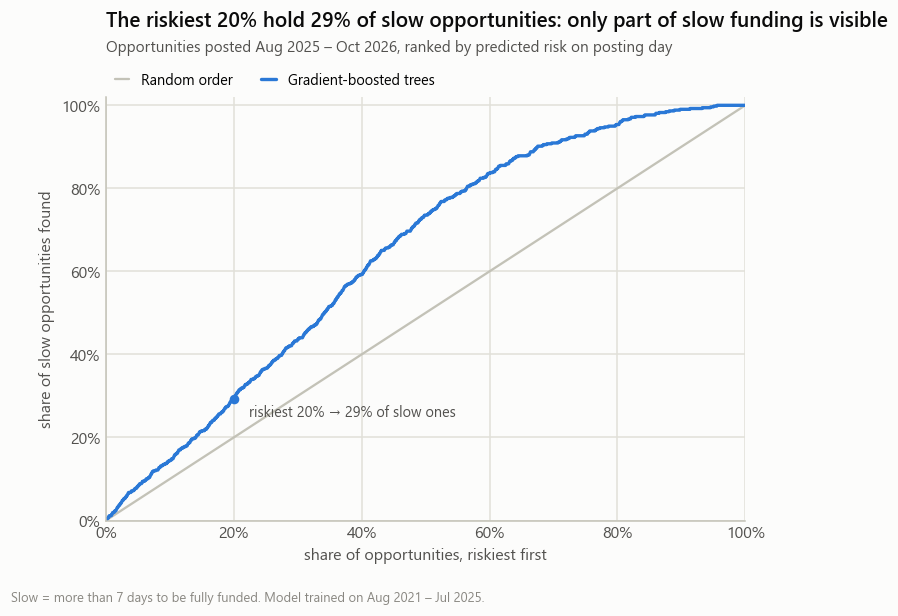

In [44]:
best_name = best.Model
order = np.argsort(-risk[best_name])
caught = np.concatenate([[0], np.cumsum(y[test].to_numpy()[order]) / y[test].sum()])
share = np.linspace(0, 1, len(caught))

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(share, share, color=viz.CONTEXT, lw=1.5, label="Random order")
ax.plot(share, caught, color=viz.BLUE, lw=2.2, label=best_name)
at = np.searchsorted(share, FLAG)
ax.scatter([FLAG], [caught[at]], color=viz.BLUE, zorder=3, s=28)
ax.annotate(f"riskiest 20% → {caught[at]:.0%} of slow ones", (FLAG, caught[at]), xytext=(10, -4), textcoords="offset points",
            fontsize=9.5, color=viz.INK_2, va="top")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("share of opportunities, riskiest first")
ax.set_ylabel("share of slow opportunities found")
ax.legend()
viz.title(ax, f"The riskiest 20% hold {caught[at]:.0%} of slow opportunities: only part of slow funding is visible",
          "Opportunities posted Aug 2025 – Oct 2026, ranked by predicted risk on posting day")
viz.note(fig, "Slow = more than 7 days to be fully funded. Model trained on Aug 2021 – Jul 2025.")
viz.save(fig, "5_1_predictable")
plt.show()

half = share[np.searchsorted(caught, 0.5)]
n_top, n_slow = round(FLAG * test.sum()), int(y[test].sum())
n_found, n_random = round(caught[at] * n_slow), round(FLAG * n_slow)
viz.takeaway(f"Of the <b>{test.sum():,}</b> test opportunities, <b>{n_slow:,}</b> turned out slow. The <b>20%</b> the model rates "
             f"riskiest ({n_top:,} opportunities) hold about <b>{n_found:,}</b> of them ({caught[at]:.0%}), against about "
             f"{n_random:,} in a random order. To find half of the slow ones, the top <b>{half:.0%}</b> must be taken. "
             "Most slow opportunities look ordinary on the day they are posted: much of how donors respond depends on "
             "things this data does not record, such as how an appeal is written and shared.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">5.5</span>What drives the prediction

Each feature is shuffled in turn on the test data; the more the model's AUC drops, the more it relies on that feature. Features that belong together (the two track-record columns, the two competition columns) are shuffled together. Amount, beneficiaries and amount per beneficiary overlap, so each of them on its own looks smaller than the three together.

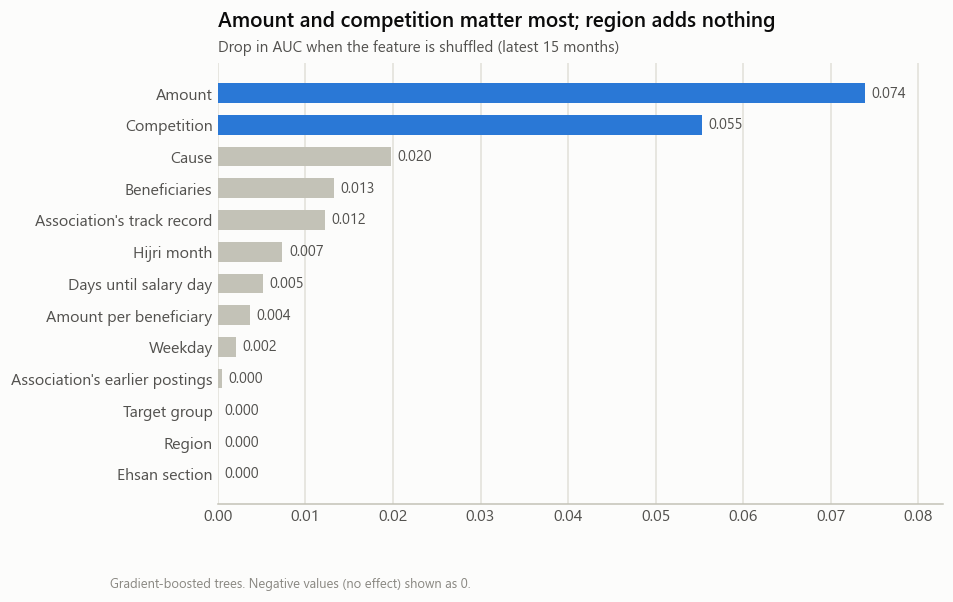

In [45]:
GROUPS = {"Amount": ["amount"], "Beneficiaries": ["beneficiaries_log"], "Amount per beneficiary": ["per_beneficiary"],
          "Association's track record": ["track_record", "track_record_n"],
          "Association's earlier postings": ["association_history"],
          "Competition": ["open_now", "posted_week"], "Days until salary day": ["to_payday"],
          "Cause": ["cause"], "Target group": ["target_group"], "Region": ["region_en"], "Ehsan section": ["section"],
          "Hijri month": ["hijri_month"], "Weekday": ["weekday"]}
model, X_test = fitted[best_name], X[test]
full_auc = roc_auc_score(y[test], risk[best_name])
rng = np.random.default_rng(0)
drops = {}
for label, cols in GROUPS.items():
    scores = []
    for _ in range(10):
        shuffled = X_test.copy()
        shuffled[cols] = X_test[cols].to_numpy()[rng.permutation(len(X_test))]
        scores.append(full_auc - roc_auc_score(y[test], model.predict_proba(shuffled)[:, 1]))
    drops[label] = np.mean(scores)
importance = pd.Series(drops).clip(lower=0).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
top2 = importance.index[:2].tolist()
viz.hbar(ax, importance.index, importance.values, highlight=top2, fmt=lambda v: f"{v:.3f}")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.2f}")
viz.title(ax, f"{top2[0]} and {top2[1].lower()} matter most; region adds nothing",
          "Drop in AUC when the feature is shuffled (latest 15 months)")
viz.note(fig, f"{best_name}. Negative values (no effect) shown as 0.")
viz.save(fig, "5_2_drivers")
plt.show()

busy = model_data.posted_week >= model_data.posted_week.quantile(0.75)
big = model_data.amount_sar >= model_data.amount_sar.quantile(0.8)
viz.takeaway(f"<b>{top2[0]}</b> and <b>{top2[1].lower()}</b> carry most of the prediction. Competition works the "
             f"opposite way to what one might expect: opportunities posted in the busiest quarter of weeks are slow "
             f"{y[busy].mean():.0%} of the time, against {y[~busy].mean():.0%} otherwise, because busy weeks (above all "
             f"Ramadan) are when donors are most active. The largest fifth of opportunities are slow "
             f"{y[big].mean():.0%} of the time, against {y[~big].mean():.0%} for the rest. Hijri month counts for less "
             f"({importance['Hijri month']:.3f}) than one might expect from section 4 because competition already carries "
             "the Ramadan season. <b>Region</b> adds nothing once "
             "these are known, which agrees with section 3: donors respond about equally across regions, and the regional "
             "gap is in what gets posted.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">5.6</span>Limits of what the model shows

- **Patterns, not causes.** Large amounts are slower, and busy weeks are faster, but the model does not show that changing one of these would change the speed. Section 6 treats them as starting points.
- **Most of the slowness is unseen.** The riskiest fifth holds a little under a third of the slow opportunities. The rest depend on things the data does not hold: how the opportunity is written, shared and promoted, and current events.
- **A slow track record is not a verdict on an association.** It describes how donors have responded to its appeals so far. It points to associations that may need help writing and promoting them, not to ones that deserve fewer chances; the same holds for slower causes such as housing.
- **Completed opportunities only.** The data holds opportunities that were fully funded, so the competition count leaves out the few that were still open when the data was collected.
- **Time.** Donor behaviour on Ehsan changes from year to year (5.1 and 5.2 both show it), so these patterns describe 2021–2026 and should be checked again on newer data.

## <span style="display:inline-block;min-width:1.8em;padding:.1em .4em;margin-right:.5em;border-radius:.4em;background:#3987e5;color:#fff;text-align:center;font-weight:600">6</span>Recommendations
<div style="border-bottom:1px solid rgba(127,127,127,.35);margin:-4px 0 14px"></div>

The question was: **where should the next riyal go?** Sections 2–5 give the answer in four parts, each for whoever can act on it:

- **A. Funders and the National Center for Non-Profit Sector (NCNP):** where grants and matching funds go.
- **B. NCNP, with Ehsan:** the association side, where few associations post.
- **C. Associations:** timing of postings and appeals.
- **D. Associations and funders:** what the model shows about how donors respond.

Every number in the table is computed above, so it stays correct when the notebook is re-run. The last column says how to tell, a year later, whether the action worked.

In [46]:
pair_names = lambda t: ", ".join(f"{r} {c.lower()}" for r, c in zip(t.Region, t.Cause))
worst = neglected.loc[neglected["vs national"].str.replace(" pts", "").astype(int).idxmin()]   # slowest against national
supply_regions = supply.Region.value_counts()
seasoned = model_data.track_record_n >= np.log1p(5)      # associations with at least 5 completed opportunities before
slow_record = seasoned & (model_data.track_record >= model_data.track_record[seasoned].quantile(0.75))

R = [
    ("A1", "Funders, NCNP",
     f"Grants or matching funds for the {len(neglected)} neglected pairs: {pair_names(neglected)}.",
     f"Little is posted there and donors are slow to fund it. In {worst.Region} {worst.Cause.lower()}, "
     f"{worst['Funded within a week']:.0%} are funded within a week ({worst['vs national']} vs national). (3.3–3.4)",
     "Funded-within-a-week share rises to the national level for that cause."),
    ("A2", "Funders, NCNP",
     f"For the {len(supply)} supply gaps, fund associations' capacity to prepare and post opportunities "
     "(staff, needs assessment, report writing), not donations.",
     f"Donors fund what is posted there at the normal pace or faster; the gap is in what is posted. Region adds nothing "
     f"to the model once other features are known (5.5). They are in "
     f"{', '.join(f'{r} ({n})' for r, n in supply_regions.items() if n > 1)}. (3.4)",
     "Value posted per resident (coverage) moves toward 1.0 in those pairs."),
    ("B3", "NCNP, with Ehsan",
     "Eastern and Riyadh: bring more local associations onto Ehsan; in Eastern, also help registered associations "
     "post their first projects.",
     f"Partner associations per resident: Eastern {parts.loc['Eastern', 'Partners per resident']:.2f}×, Riyadh "
     f"{parts.loc['Riyadh', 'Partners per resident']:.2f}× the national level; in Eastern only "
     f"{parts.loc['Eastern', 'Share that post projects']:.2f}× the national share of them post projects. (3.5)",
     "Partner associations per resident, and the share that post, in both regions."),
    ("B4", "NCNP, with Ehsan", "Tabuk: help associations combine related needs into larger opportunities.",
     f"Average opportunity size in Tabuk is {parts.loc['Tabuk', 'Average size']:.2f}× the national level. (3.5)",
     "Average opportunity size in Tabuk."),
    ("B5", "NCNP, with Ehsan", "Follow up with associations after their first project, to support a second.",
     f"{(per_assoc == 1).mean():.0%} of associations that posted a project completed only one. (3.5)",
     "Share of associations with only one completed project."),
    ("C6", "Associations",
     f"Do not rely on {SHABAN} for urgent needs; post them in Ramadan, or seek matching funds for {SHABAN} postings.",
     f"{SHABAN} is below its year's pace in {(slow_col < 0).sum()} of {len(slow_col)} years "
     f"({months.vs_year[SHABAN]:+.0f} points); Ramadan is {months.vs_year['Ramadan']:+.0f} points despite "
     f"{months.per_month['Ramadan'] / typical:.0f}× the postings. (4.2)",
     f"Within-a-week share of {SHABAN} postings against their year."),
    ("C7", "Associations", f"Send appeals and reminders around the 27th (salary day) and on {completed_on.idxmax()}s.",
     f"Completions on the 27th are {by_day[27]:.1f}× an average day; on {completed_on.idxmax()}s "
     f"{completed_on.max():.1f}×. (4.3–4.4)",
     "Speed of opportunities whose appeals were timed this way, against others."),
    ("D8", "Associations", "Where a need allows it, split a very large amount into phases.",
     f"The largest fifth of opportunities are slow {y[big].mean():.0%} of the time, against {y[~big].mean():.0%}; "
     f"{importance.index[0].lower()} is the model's strongest feature. (5.5)",
     "Speed of phased opportunities against single large ones."),
    ("D9", "Associations", "Do not hold back postings to avoid busy weeks.",
     f"Opportunities posted in the busiest quarter of weeks are slow {y[busy].mean():.0%} of the time, against "
     f"{y[~busy].mean():.0%}: busy weeks are when donors are most active. (5.5)",
     "–"),
    ("D10", "Funders, NCNP",
     "Offer associations whose appeals have been slow help with writing and promoting them.",
     f"Among associations with at least 5 earlier completed opportunities, the slowest quarter by track record are "
     f"slow {y[slow_record].mean():.0%} of the time, against {y[seasoned & ~slow_record].mean():.0%} for the rest. (5.5)",
     "Track record of supported associations, a year later."),
]
recs = pd.DataFrame(R, columns=["#", "Who acts", "What to do", "Evidence (section)", "How to tell it worked"])
display(viz.table(recs, caption="Recommendations"))
recs.to_csv(ROOT / "outputs/recommendations.csv", index=False, encoding="utf-8-sig")

#,Who acts,What to do,Evidence (section),How to tell it worked
A1,"Funders, NCNP","Grants or matching funds for the 3 neglected pairs: Eastern feeding, Jazan religious, Eastern housing.","Little is posted there and donors are slow to fund it. In Eastern housing, 37% are funded within a week (-21 pts vs national). (3.3–3.4)",Funded-within-a-week share rises to the national level for that cause.
A2,"Funders, NCNP","For the 12 supply gaps, fund associations' capacity to prepare and post opportunities (staff, needs assessment, report writing), not donations.","Donors fund what is posted there at the normal pace or faster; the gap is in what is posted. Region adds nothing to the model once other features are known (5.5). They are in Eastern (4), Riyadh (4), Makkah (2), Madinah (2). (3.4)",Value posted per resident (coverage) moves toward 1.0 in those pairs.
B3,"NCNP, with Ehsan","Eastern and Riyadh: bring more local associations onto Ehsan; in Eastern, also help registered associations post their first projects.","Partner associations per resident: Eastern 0.43×, Riyadh 0.51× the national level; in Eastern only 0.75× the national share of them post projects. (3.5)","Partner associations per resident, and the share that post, in both regions."
B4,"NCNP, with Ehsan",Tabuk: help associations combine related needs into larger opportunities.,Average opportunity size in Tabuk is 0.82× the national level. (3.5),Average opportunity size in Tabuk.
B5,"NCNP, with Ehsan","Follow up with associations after their first project, to support a second.",35% of associations that posted a project completed only one. (3.5),Share of associations with only one completed project.
C6,Associations,"Do not rely on Sha'ban for urgent needs; post them in Ramadan, or seek matching funds for Sha'ban postings.",Sha'ban is below its year's pace in 5 of 5 years (-14 points); Ramadan is +7 points despite 4× the postings. (4.2),Within-a-week share of Sha'ban postings against their year.
C7,Associations,Send appeals and reminders around the 27th (salary day) and on Fridays.,Completions on the 27th are 1.6× an average day; on Fridays 1.5×. (4.3–4.4),"Speed of opportunities whose appeals were timed this way, against others."
D8,Associations,"Where a need allows it, split a very large amount into phases.","The largest fifth of opportunities are slow 35% of the time, against 29%; amount is the model's strongest feature. (5.5)",Speed of phased opportunities against single large ones.
D9,Associations,Do not hold back postings to avoid busy weeks.,"Opportunities posted in the busiest quarter of weeks are slow 25% of the time, against 32%: busy weeks are when donors are most active. (5.5)",–
D10,"Funders, NCNP",Offer associations whose appeals have been slow help with writing and promoting them.,"Among associations with at least 5 earlier completed opportunities, the slowest quarter by track record are slow 47% of the time, against 27% for the rest. (5.5)","Track record of supported associations, a year later."


### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">6.1</span>The answer in one picture

The region × cause pairs to prioritise, from section 3. **Coverage** is the value posted per resident against the national rate for the same cause: 1.0 is the fair share, 0.5 is half of it.

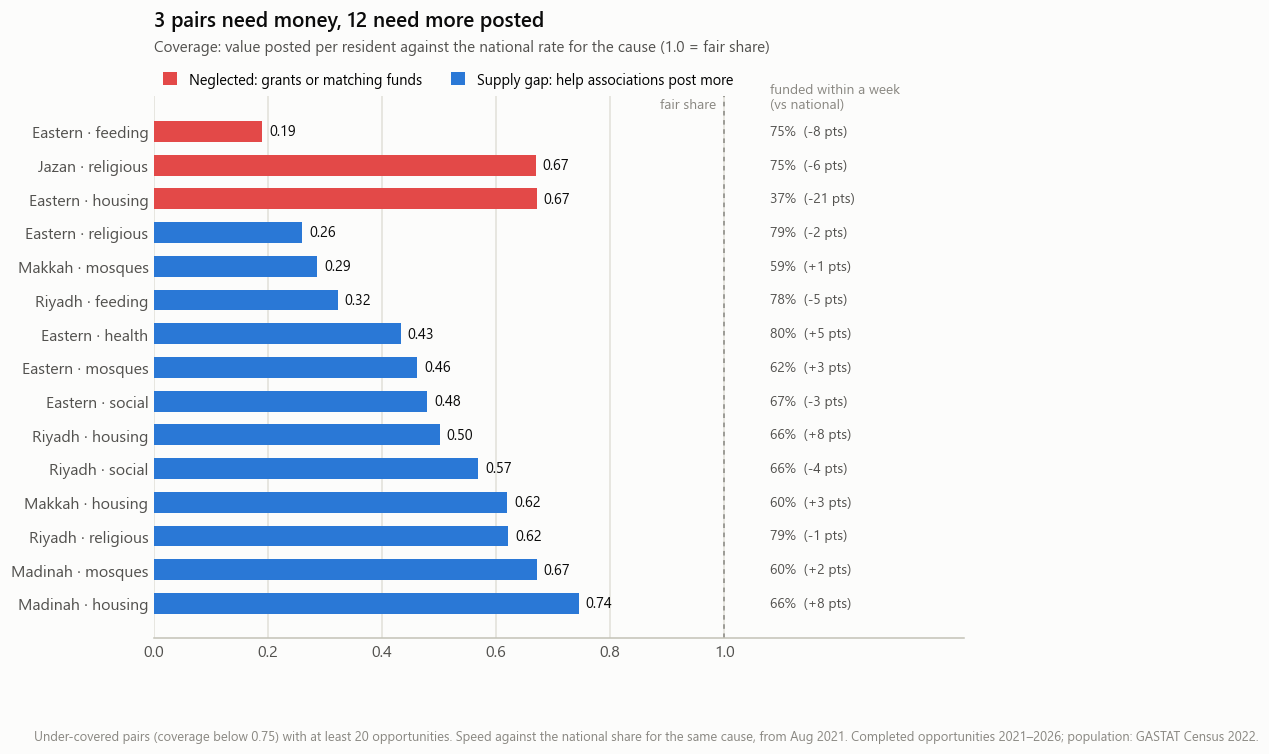

In [47]:
pairs = pd.concat([neglected.assign(kind="Neglected: grants or matching funds"),
                   supply.assign(kind="Supply gap: help associations post more")])
pairs["label"] = pairs.Region + " · " + pairs.Cause.str.lower()
pairs = pairs.iloc[::-1]   # first row drawn at the top
kind_color = {"Neglected: grants or matching funds": viz.DIVERGING[2],
              "Supply gap: help associations post more": viz.BLUE}

fig, ax = plt.subplots(figsize=(9.5, 6.4))
for kind, color in kind_color.items():
    rows = pairs.kind == kind
    ax.barh(np.flatnonzero(rows), pairs.Coverage[rows], height=0.62, color=color, label=kind)
for i, (v, week, vs) in enumerate(zip(pairs.Coverage, pairs["Funded within a week"], pairs["vs national"])):
    ax.text(v + 0.012, i, f"{v:.2f}", va="center", fontsize=9.5, color=viz.INK)
    ax.text(1.08, i, f"{week:.0%}  ({vs})", va="center", fontsize=9, color=viz.INK_2)   # own column, right of the line
ax.text(1.08, len(pairs) - 0.4, "funded within a week\n(vs national)", va="bottom", fontsize=9, color=viz.MUTED)
ax.set_yticks(range(len(pairs)), pairs.label)
ax.axvline(1, color=viz.MUTED, lw=1, ls=(0, (3, 3)))
ax.text(0.985, len(pairs) - 0.4, "fair share", ha="right", va="bottom", fontsize=9, color=viz.MUTED)
ax.set_xlim(0, 1.42)
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.1f}")
viz.only_grid(ax, "x")
ax.legend()
viz.title(ax, f"{len(neglected)} pairs need money, {len(supply)} need more posted",
          "Coverage: value posted per resident against the national rate for the cause (1.0 = fair share)")
viz.note(fig, "Under-covered pairs (coverage below 0.75) with at least 20 opportunities. Speed against the national "
              "share for the same cause, from Aug 2021. Completed opportunities 2021–2026; population: GASTAT Census 2022.")
viz.save(fig, "6_1_priorities")
plt.show()

by_region = pairs.Region.value_counts()
viz.takeaway(f"<b>The next riyal should go first to the {by_region.index[0]} Region</b>, which has <b>{by_region.iloc[0]}</b> "
             f"of the {len(pairs)} priority pairs, then "
             + ", ".join(f"{r} ({n})" for r, n in by_region.iloc[1:].items()) + ". "
             f"In most of them donors already respond; "
             f"the money is best spent helping associations post. Only in <b>{len(neglected)}</b> pairs "
             f"({pair_names(neglected)}) are grants or matching funds needed because donors are slow as well.")

### <span style="display:inline-block;padding:.05em .45em;margin-right:.5em;border-radius:.4em;background:rgba(57,135,229,.15);color:#3987e5;font-weight:600">6.2</span>Before acting on these

- The data covers **project opportunities on Ehsan** only. A region that posts little on Ehsan may be served through other channels (other platforms, direct giving, government programmes), so a low coverage figure is a reason to look closer, not proof of unmet need.
- Partner associations are counted by **headquarters**, and the map was read by hand (3,571 of 3,847 placed).
- Timing and model findings are **patterns, not causes**; the "How to tell it worked" column is there so each action can be checked.
- More detail is in the appendix.

## Appendix: data collection, ethics and limits

### Data and how it was collected

Ehsan is server-rendered, with no public API. The data was collected with a polite scraper (`scraper/`, 1.5 s between requests, every page cached) that reads:

| Source page | What it gives |
|---|---|
| Listing pages (`/projects`, `/mosques`, `/housing` and their completed archives) | case id, title, progress |
| Completed report page (`/CompletedInitiatives/Report…`) | region / city, association, beneficiary nationality and count, **publish date, completion date**, total amount |
| Active detail page + a JavaScript-loaded fragment | target, collected, city, association, beneficiaries |
| `/visit-count/…` | page visits |
| GASTAT Census 2022 (`data_raw/gastat/`) | population of the 13 regions, Saudi and non-Saudi, for per-person figures. Source and checks in `data_raw/gastat/SOURCE.md` |
| Ehsan statistics page (`/dashboard`), read 27 Oct 2026 (`data_raw/ehsan_dashboard/`) | platform totals since 2021 and partner associations per region (read by hand from the map, with screenshots). Details in `data_raw/ehsan_dashboard/SOURCE.md` |

The scraper produced one raw table, which is this notebook's input: `data_raw/2026-10-23/opportunities.csv`. The raw HTML (about 2 GB) is not needed to run this notebook. See `README.md` to re-collect it.

**Scope.** This analysis covers Ehsan's **Projects** (المشاريع) area under "donation opportunities": general projects, mosque care and housing. Everything else on the platform is out of scope:

| Ehsan section | What it is | Why it is out of scope |
|---|---|---|
| Orphan sponsorship (كفالة الأيتام) | monthly sponsorship of individual children (~198,000 completed) | the archive server takes ~11 s per page (~70 h in total), its cards carry no region, and every page describes a child |
| Tayassarat (تيسرت), Forijat (فرجت) | paying individual debts; releasing people jailed over debts | individual people's cases |
| Kaffarat (الكفارات) | religious expiation payments | pooled fixed-price payments, with no place, target or association |
| Relief (إغاثة) | international aid such as wells abroad | outside Saudi regions |
| Waqf (الوقف) and donation services (zakat, gifts, adahi, recurring giving) | endowments and payment services | not individual opportunities to compare |

So the findings describe **project opportunities on Ehsan**, not all giving on the platform.

### Ethics and limits

- **No personal data.** Titles and descriptions of individual family cases were dropped at collection. All analysis is aggregated.
- **Platform bias.** Ehsan shows what associations *post and get funded on Ehsan*, not total need in society. Regions with fewer associations on the platform can look "low need" when they are really under-served. This is treated as a finding, not just a caveat.
- **Survivorship.** The archive holds opportunities that were fully funded. "Success" here means *how fast* an opportunity was funded.